# Лабораторная работа № 2

## Обучение нейросетевых моделей для анализа и прогнозирования временных рядов

### Вариант 7

## Цель работы

Получить практические навыки подготовки временных рядов и построения нейросетевых регрессионных моделей для прогнозирования метеорологических показателей. Исследовать возможности полносвязных сетей прямого распространения (MLP), рекуррентных сетей SimpleRNN, а также сетей с ячейками LSTM.

## Задание

- получить исторические ежедневные метеорологические данные для назначенного города и выполнить их первичный анализ;
- сформировать обучающие примеры методом скользящего временного окна;
- реализовать четыре типа регрессионных моделей: MLP, SimpleRNN, LSTM и модель с двумя последовательными слоями LSTM;
- решить две задачи: прогноз температуры на следующий день и прогноз средней температуры за следующие семь дней;
- исследовать влияние длины входного окна, числа нейронов и ячеек, глубины сети, оптимизатора и Dropout;
- сравнить модели с наивными прогнозами, оценить качество на тестовом интервале и проанализировать переобучение.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", message=".*RNN module weights.*")

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

In [2]:
# Дополнительные библиотеки: метрики, масштабирование, время обучения, тепловая карта
import time

import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

## Описание набора данных

- Источник: Meteostat, bulk-выгрузка ежедневных наблюдений, https://dev.meteostat.net/bulk/daily.html
- Станция: 37171, Adler (Адлер, район Сочи), WMO 37171, ICAO URSS
- Координаты станции: 43.4333 с.ш., 39.9000 в.д., высота 16 м
- Часовой пояс: Europe/Moscow
- Период: 2016-01-01 ... 2025-12-31, 3653 календарных дня
- Целевой показатель: `tavg`, среднесуточная температура воздуха, °C

Open-Meteo archive на момент выполнения работы отвечал ошибкой 503, поэтому использован другой открытый источник, который допускается заданием. Станция Адлер находится в городском округе Сочи, ряд полный по целевому показателю.

Таблица полей:

| Поле | Содержание | Единица |
|---|---|---|
| date | дата наблюдения | - |
| tavg | среднесуточная температура воздуха | °C |
| tmin | минимальная температура воздуха за сутки | °C |
| tmax | максимальная температура воздуха за сутки | °C |
| prcp | сумма осадков за сутки | мм |
| snow | высота снежного покрова | мм |
| wdir | среднее направление ветра | градусы |
| wspd | средняя скорость ветра | км/ч |
| wpgt | максимальный порыв ветра | км/ч |
| pres | атмосферное давление на уровне станции | гПа |
| tsun | продолжительность солнечного сияния | мин |

В базовом эксперименте используется только история `tavg`. Остальные признаки приведены для описания набора и матрицы корреляций.

In [3]:
# Файл скачан заранее: папка labs/data
DATA_FILE = DATA_DIR / "sochi-weather" / "sochi-daily-meteostat-2016-2025.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Не найден файл с данными: " + str(DATA_FILE) + "\n"
        "Скачайте daily-выгрузку Meteostat для станции 37171: "
        "https://bulk.meteostat.net/v2/daily/37171.csv.gz\n"
        "Оставьте столбцы date, tavg, tmin, tmax, prcp, snow, wdir, wspd, wpgt, pres, tsun "
        "и сохраните файл как sochi-daily-meteostat-2016-2025.csv."
    )

weather = pd.read_csv(DATA_FILE, parse_dates=["date"], encoding="utf-8")
weather = weather.sort_values("date").reset_index(drop=True)

print("Размер таблицы:", weather.shape)
display(weather.head(10))
weather.info()
display(weather.describe().T.round(2))

Размер таблицы: (3653, 11)


,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2016-01-01,-1.8,-5.0,1.5,0.8,10.0,353.0,10.7,NaN,NaN,NaN
1,2016-01-02,-1.6,-6.5,2.7,0.0,NaN,25.0,9.8,NaN,NaN,NaN
2,2016-01-03,-2.4,-6.0,0.4,8.9,51.0,15.0,9.6,NaN,NaN,NaN
3,2016-01-04,1.4,-7.0,6.0,0.5,99.0,82.0,20.0,NaN,NaN,NaN
4,2016-01-05,8.9,3.4,13.0,NaN,NaN,120.0,25.8,NaN,NaN,NaN
5,2016-01-06,7.8,6.0,11.1,10.9,NaN,87.0,14.4,NaN,NaN,NaN
6,2016-01-07,12.1,6.4,17.0,NaN,NaN,82.0,17.6,NaN,NaN,NaN
7,2016-01-08,10.3,6.0,16.1,13.5,NaN,18.0,20.4,NaN,NaN,NaN
8,2016-01-09,5.6,4.0,7.4,23.1,NaN,NaN,8.6,NaN,NaN,NaN
9,2016-01-10,5.9,3.0,10.0,5.1,NaN,67.0,12.6,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3653 non-null   datetime64[us]
 1   tavg    3653 non-null   float64       
 2   tmin    3653 non-null   float64       
 3   tmax    3652 non-null   float64       
 4   prcp    3452 non-null   float64       
 5   snow    24 non-null     float64       
 6   wdir    3394 non-null   float64       
 7   wspd    3628 non-null   float64       
 8   wpgt    0 non-null      float64       
 9   pres    3554 non-null   float64       
 10  tsun    0 non-null      float64       
dtypes: datetime64[us](1), float64(10)
memory usage: 314.1 KB


,count,mean,min,25%,50%,75%,max,std
date,3653,2020-12-31 00:00:00,2016-01-01 00:00:00,2018-07-02 00:00:00,2020-12-31 00:00:00,2023-07-02 00:00:00,2025-12-31 00:00:00,NaN
tavg,3653.0,15.185053,-3.4,9.3,14.6,21.8,29.3,7.186957
tmin,3653.0,11.34536,-7.0,5.8,10.8,18.0,26.0,7.062704
tmax,3652.0,19.731216,0.4,13.7,19.7,26.3,36.5,7.42543
prcp,3452.0,3.98511,0.0,0.0,0.0,2.0,111.0,9.856567
snow,24.0,50.875,10.0,20.0,41.0,84.0,150.0,39.52689
wdir,3394.0,130.811727,0.0,49.0,82.0,211.25,359.0,116.958555
wspd,3628.0,11.649421,3.8,9.8,11.4,13.2,29.7,2.942219
wpgt,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pres,3554.0,1015.388351,996.2,1010.9,1015.0,1019.6,1034.5,6.040176


## Анализ данных

### Проверка календаря, пропусков и дубликатов

In [4]:
# Строим полный календарь и проверяем, что каждый день присутствует ровно один раз
expected_dates = pd.date_range(weather["date"].min(), weather["date"].max(), freq="D")
missing_dates = expected_dates.difference(weather["date"])
duplicate_dates = int(weather["date"].duplicated().sum())

print("Первый день:", weather["date"].min().date())
print("Последний день:", weather["date"].max().date())
print("Ожидалось дней:", len(expected_dates))
print("Фактически строк:", len(weather))
print("Пропущенных календарных дней:", len(missing_dates))
print("Дубликатов дат:", duplicate_dates)

missing = weather.isna().sum().to_frame(name="пропусков")
missing["доля, %"] = (missing["пропусков"] / len(weather) * 100).round(2)
display(missing)

Первый день: 2016-01-01
Последний день: 2025-12-31
Ожидалось дней: 3653
Фактически строк: 3653
Пропущенных календарных дней: 0
Дубликатов дат: 0


,пропусков,"доля, %"
date,0,0.00
tavg,0,0.00
tmin,0,0.00
tmax,1,0.03
prcp,201,5.50
snow,3629,99.34
wdir,259,7.09
wspd,25,0.68
wpgt,3653,100.00
pres,99,2.71


**Результат:** пропусков и дубликатов в данных нет.

### Выбросы в целевом показателе

Выбросы ищем по правилу 1,5 межквартильного размаха. Для температуры экстремальные, но реальные значения не удаляем: это погодные аномалии, а не ошибки ввода. Решение объясняется в выводе по анализу.

In [5]:
# Выбросы по правилу 1,5 IQR: считаем границы, но реальные аномалии не удаляем
q1 = weather["tavg"].quantile(0.25)
q3 = weather["tavg"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = weather[(weather["tavg"] < lower_bound) | (weather["tavg"] > upper_bound)]

print("Q1 =", round(float(q1), 2), "Q3 =", round(float(q3), 2), "IQR =", round(float(iqr), 2))
print("Границы:", round(float(lower_bound), 2), "..", round(float(upper_bound), 2))
print("Выбросов:", len(outliers))
display(outliers[["date", "tavg"]].head(10))

Q1 = 9.3 Q3 = 21.8 IQR = 12.5
Границы: -9.45 .. 40.55
Выбросов: 0


,date,tavg


**Результат:** выбросов нет.

### График временного ряда

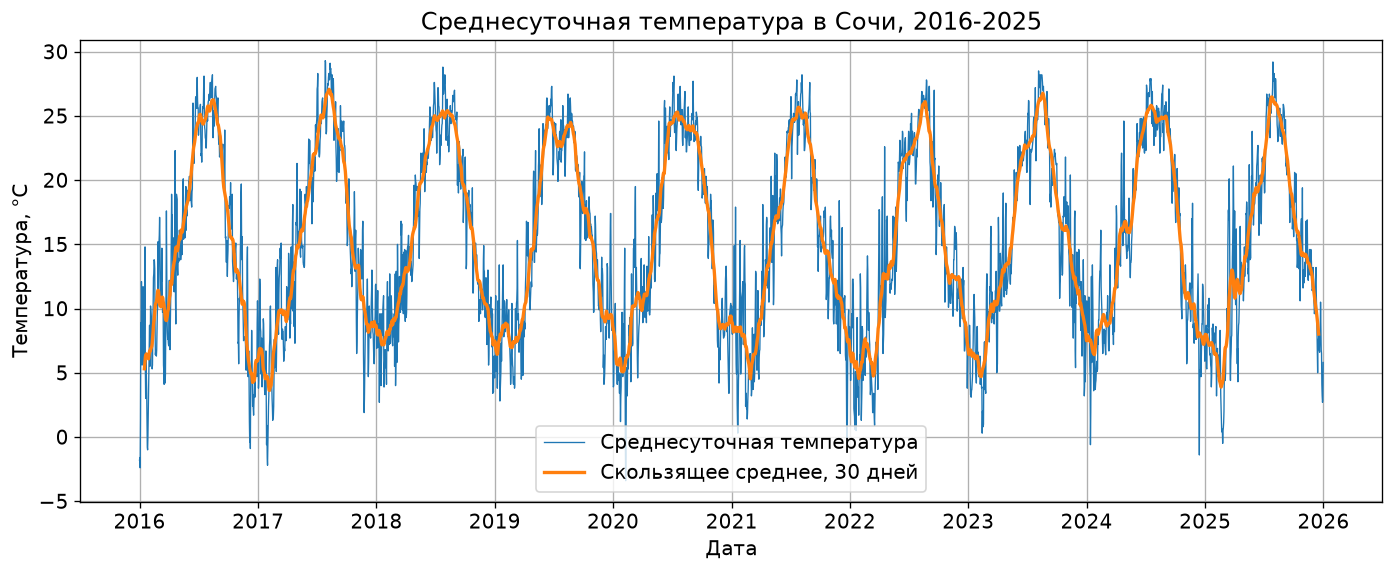

In [6]:
# Ряд целиком и сглаженное скользящее среднее за 30 дней
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weather["date"], weather["tavg"], color="tab:blue", linewidth=0.8, label="Среднесуточная температура")
ax.plot(
    weather["date"],
    weather["tavg"].rolling(30, center=True).mean(),
    color="tab:orange",
    linewidth=2,
    label="Скользящее среднее, 30 дней",
)
ax.set_title("Среднесуточная температура в Сочи, 2016-2025")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.legend()
fig.savefig(FIGURES_DIR / "lab2-series.png", bbox_inches="tight")
plt.show()

**Результат:** Выражен годовой цикл; диапазон -3,4 ... 29,3 °C, среднее 15,19 °C. Межгодовой тренд слабый.

### Сезонность и годовой ход

Ящики с усами по месяцам показывают годовой цикл. Отдельная таблица средних значений по годам нужна, чтобы увидеть межгодовые различия: тест должен быть сопоставим по сезону с обучением.

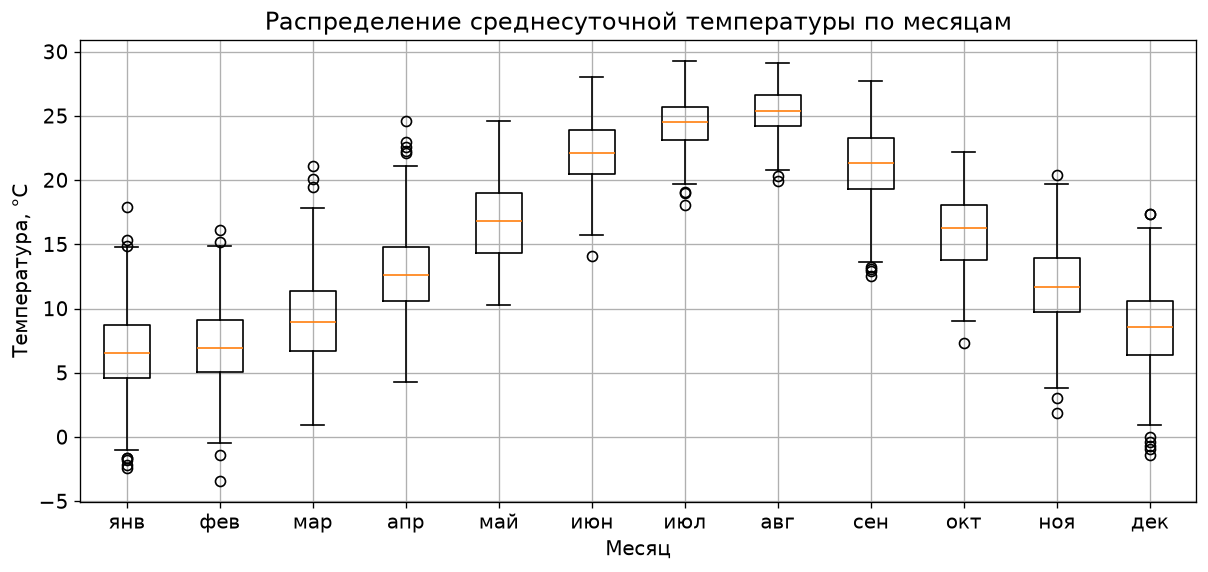

,"средняя температура, °C"
date,
2016,14.83
2017,14.94
2018,16.19
2019,15.48
2020,15.38
2021,14.69
2022,14.51
2023,15.29
2024,15.69


In [7]:
# Сезонность: распределение температуры по месяцам и средние по годам
weather["month"] = weather["date"].dt.month
month_names = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
monthly = [weather.loc[weather["month"] == month, "tavg"].to_numpy() for month in range(1, 13)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(monthly, tick_labels=month_names, showfliers=True)
ax.set_title("Распределение среднесуточной температуры по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Температура, °C")
fig.savefig(FIGURES_DIR / "lab2-monthly-box.png", bbox_inches="tight")
plt.show()

annual_mean = weather.groupby(weather["date"].dt.year)["tavg"].mean().round(2)
display(annual_mean.to_frame("средняя температура, °C"))

**Результат:** боксплот подтверждает выраженную сезонность: медианные температуры минимальны в январе–феврале (≈ +6…+7 °C) и максимальны в августе (≈ +25…+26 °C), ход медиан по месяцам гладкий, близкий к синусоиде. Внутри месячная изменчивость неоднородна: зимой и в переходные месяцы (март, апрель, октябрь, ноябрь, декабрь) разброс наибольший (IQR ≈ 4–5 °C, усы до −3…+1 °C), летом в июле–августе — наименьший (IQR ≈ 2–3 °C), т.е. зима «неустойчивее» лета. В большинстве месяцев присутствуют единичные выбросы (точки) — короткие аномальные потепления и похолодания, согласующиеся с выводом об отсутствии грубых ошибок в данных.

### Корреляции и автокорреляция

Матрица корреляций показывает, насколько дополнительные погодные признаки связаны с целевым показателем. Автокорреляция объясняет, почему наивный прогноз является сильным конкурентом и почему окно длины 7-60 дней содержит полезную информацию.

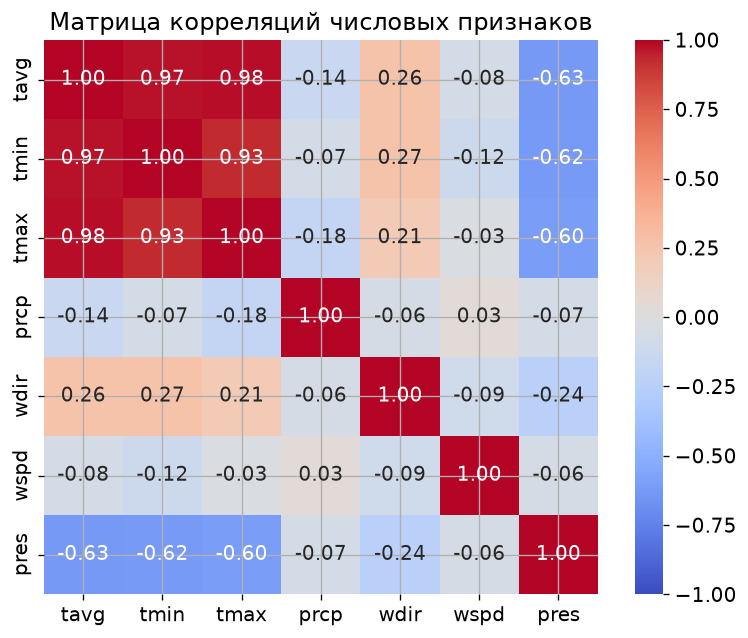

In [8]:
# Корреляционная матрица: какие признаки связаны с целевой температурой
numeric_columns = ["tavg", "tmin", "tmax", "prcp", "wdir", "wspd", "pres"]
corr = weather[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Матрица корреляций числовых признаков")
fig.savefig(FIGURES_DIR / "lab2-correlation.png", bbox_inches="tight")
plt.show()

**Результат:** целевой признак tavg почти полностью определяется температурами tmin и tmax (r = 0.97 и 0.98 — мультиколлинеарность, их лучше не подавать вместе как независимые признаки), умеренно отрицательно связан с давлением pres (r = −0.63, отражает сезонную связь: тёплый сезон — пониженное давление) и слабо — с направлением ветра wdir (r = 0.26). Осадки prcp и скорость ветра wspd с температурой практически не связаны (|r| ≤ 0.18), как и между собой, т.е. как предикторы температуры они малоинформативны.

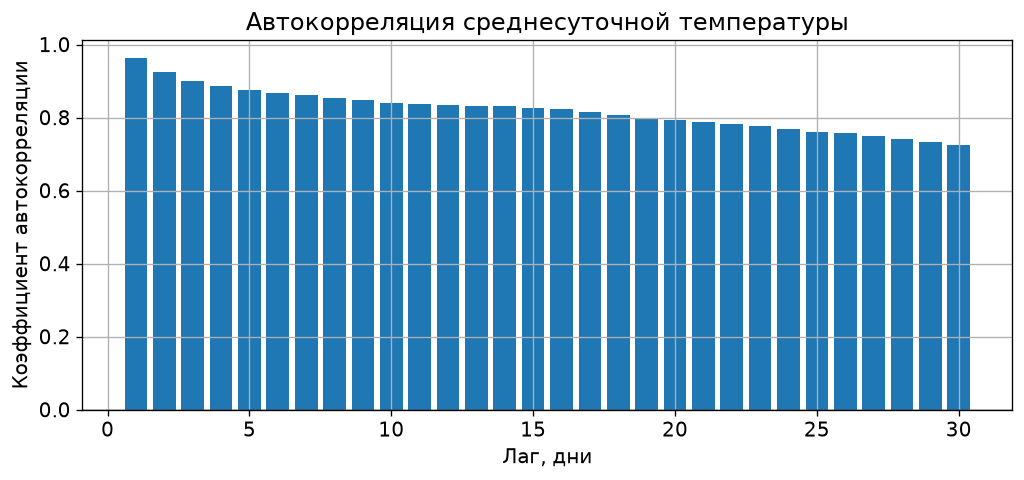

Автокорреляция при лаге 1: 0.964
Автокорреляция при лаге 7: 0.86
Автокорреляция при лаге 30: 0.726


In [9]:
# Автокорреляция: насколько прошлые значения полезны для прогноза
lags = np.arange(1, 31)
acf = np.array([weather["tavg"].autocorr(lag=int(lag)) for lag in lags])

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lags, acf, color="tab:blue")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Автокорреляция среднесуточной температуры")
ax.set_xlabel("Лаг, дни")
ax.set_ylabel("Коэффициент автокорреляции")
fig.savefig(FIGURES_DIR / "lab2-autocorrelation.png", bbox_inches="tight")
plt.show()

print("Автокорреляция при лаге 1:", round(float(acf[0]), 3))
print("Автокорреляция при лаге 7:", round(float(acf[6]), 3))
print("Автокорреляция при лаге 30:", round(float(acf[29]), 3))

**Результат:** автокорреляция среднесуточной температуры затухает очень медленно: 0.964 на лаге 1, 0.86 на лаге 7 и 0.726 на лаге 30. Это означает сильную инерционность ряда: значение за предыдущий день почти полностью определяет текущее, поэтому наивный прогноз («завтра как сегодня») — сильный базовый конкурент, а скользящее окно длиной 7–60 дней действительно содержит полезную информацию для модели; высокое значение на лаге 30 также отражает вклад сезонной составляющей.

## Подготовка данных

### Две задачи прогнозирования

Для момента времени t входом служит последовательность предыдущих значений температуры:

$$X_t = [T(t-L), T(t-L+1), \ldots, T(t-1)]$$

Задача A, прогноз на следующий день:

$$y_t = T(t)$$

Задача B, прогноз среднего за следующие семь дней:

$$y_t = \frac{1}{7}\sum_{k=0}^{6} T(t+k)$$

Для задачи B модель выдает одно скалярное значение, это прогноз недельного среднего, а не семь отдельных дневных прогнозов.

### Разбиение по времени

Данные делятся строго хронологически: 70% train, 15% validation, 15% test. Более поздние даты всегда попадают в validation и test. При формировании окон целевой интервал должен полностью лежать внутри своей выборки. Поэтому окна, которые пересекают границу, отбрасываются, и для задачи B автоматически возникает зазор не меньше семи дней.

In [10]:
# Хронологическое разбиение 70/15/15: перемешивать временной ряд нельзя
n_days = len(weather)
train_size = int(n_days * 0.70)
val_size = int(n_days * 0.15)

train_end = weather.loc[train_size - 1, "date"]
val_start = weather.loc[train_size, "date"]
val_end = weather.loc[train_size + val_size - 1, "date"]
test_start = weather.loc[train_size + val_size, "date"]
test_end = weather.loc[n_days - 1, "date"]

split_table = pd.DataFrame({
    "Выборка": ["train", "validation", "test"],
    "Начало": [weather.loc[0, "date"], val_start, test_start],
    "Конец": [train_end, val_end, test_end],
    "Дней": [train_size, val_size, n_days - train_size - val_size],
})
display(split_table)
split_table.to_csv(RESULTS_DIR / "lab2-splits.csv", index=False, encoding="utf-8")

,Выборка,Начало,Конец,Дней
0,train,2016-01-01,2022-12-31,2557
1,validation,2023-01-01,2024-06-30,547
2,test,2024-07-01,2025-12-31,549


train: 2557 дней, средняя температура 15.15 °C, диапазон -3.4 ... 29.3 °C
validation: 547 дней, средняя температура 14.71 °C, диапазон -0.6 ... 28.5 °C
test: 549 дней, средняя температура 15.84 °C, диапазон -1.4 ... 29.2 °C


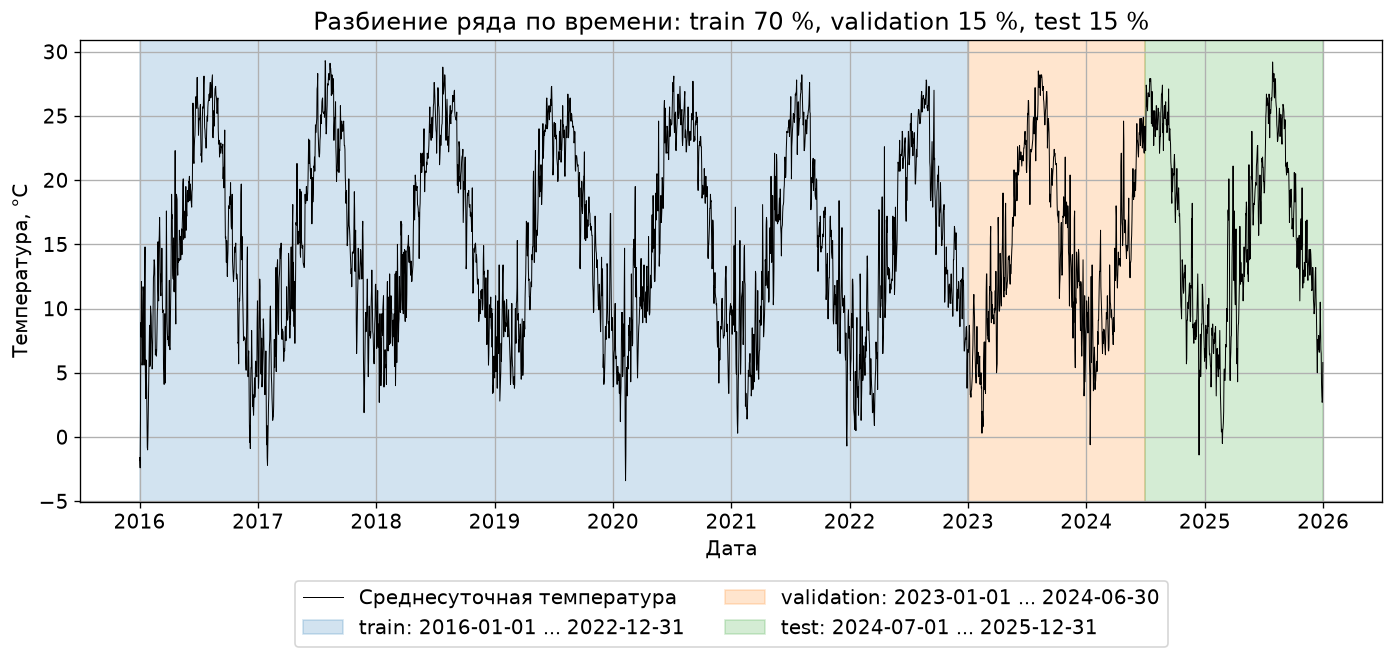

In [11]:
import matplotlib.dates as mdates

# Ряд с закрашенными интервалами train, validation и test: видно, что
# выборки идут друг за другом по времени и самые поздние даты отложены для проверки
split_periods = [
    ("train", weather.loc[0, "date"], train_end, "tab:blue"),
    ("validation", val_start, val_end, "tab:orange"),
    ("test", test_start, test_end, "tab:green"),
]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weather["date"], weather["tavg"], color="black", linewidth=0.6, label="Среднесуточная температура")
for split_name, period_start, period_end, period_color in split_periods:
    # Закрашиваем интервал до конца последнего дня, чтобы между выборками не было щели
    ax.axvspan(period_start, period_end + pd.Timedelta(days=1), color=period_color, alpha=0.2,
               label=f"{split_name}: {period_start:%Y-%m-%d} ... {period_end:%Y-%m-%d}")

# Средняя температура и диапазон каждой выборки: test не должен выходить за значения, известные по train
for split_name, period_start, period_end, _ in split_periods:
    period_tavg = weather.loc[weather["date"].between(period_start, period_end), "tavg"]
    print(f"{split_name}: {len(period_tavg)} дней, средняя температура {period_tavg.mean():.2f} °C, "
          f"диапазон {period_tavg.min()} ... {period_tavg.max()} °C")

ax.set_title("Разбиение ряда по времени: train 70 %, validation 15 %, test 15 %")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
# Подпись года под каждой отметкой, как на графике всего ряда
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
# Легенда под графиком, чтобы не закрывать данные
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.savefig(FIGURES_DIR / "lab2-splits.png", bbox_inches="tight")
plt.show()

**Результат:** выборки идут подряд и не пересекаются, самые поздние даты отложены для validation и test. Validation и test длятся по полтора года, поэтому в каждой есть все сезоны. Средняя температура: train 15,15 °C, validation 14,71 °C, test 15,84 °C. Test немного теплее, потому что в нем два лета и одна зима. Значения test (-1,4 ... 29,2 °C) лежат внутри диапазона train (-3,4 ... 29,3 °C): модели не нужно прогнозировать температуру, которой не было при обучении.

### Масштабирование

`StandardScaler` обучается только на обучающем интервале. Затем те же среднее и стандартное отклонение применяются к validation и test. Это исключает утечку информации из будущего. Для интерпретации метрик прогнозы возвращаются в градусы Цельсия.

In [12]:
# Масштабирование обучаем только на train, чтобы не подглядывать в val/test
scaler = StandardScaler()
train_mask_raw = weather["date"] <= train_end
scaler.fit(weather.loc[train_mask_raw, ["tavg"]])
weather["tavg_scaled"] = scaler.transform(weather[["tavg"]]).ravel()

train_tavg = weather.loc[train_mask_raw, "tavg"]
print("Среднее на train, °C:", round(float(scaler.mean_[0]), 3))
print("Стандартное отклонение на train, °C:", round(float(scaler.scale_[0]), 3))
print("Диапазон train, °C:", round(float(train_tavg.min()), 2), "..", round(float(train_tavg.max()), 2))

Среднее на train, °C: 15.147
Стандартное отклонение на train, °C: 7.227
Диапазон train, °C: -3.4 .. 29.3


### Скользящие окна

Функция ниже строит окна для выбранной задачи и длины окна. Внутри сохраняются и масштабированные значения для нейросетей, и исходные градусы для наивных прогнозов и метрик. Разбиение выполняется по целевому интервалу, а не по началу окна.

In [13]:
# Перебираемые длины скользящего окна, дни
WINDOW_LENGTHS = [7, 14, 30, 60]
# Горизонт задачи B: среднее за следующие 7 дней
WEEKLY_HORIZON = 7
# Две задачи: температура следующего дня и среднее за неделю
TASKS = ["next_day", "weekly_mean"]
TASK_TITLES = {
    "next_day": "прогноз на следующий день",
    "weekly_mean": "прогноз среднего за 7 дней",
}
MODEL_TITLES = {
    "MLP": "MLP",
    "SimpleRNN": "SimpleRNN",
    "LSTM": "LSTM",
    "StackedLSTM": "Stacked LSTM",
}


def make_task_data(task, window):
    '''Строит окна и размечает их по выборкам train, val, test, gap.'''
    values_scaled = weather["tavg_scaled"].to_numpy(dtype="float32")
    values_raw = weather["tavg"].to_numpy(dtype="float32")
    dates = pd.DatetimeIndex(weather["date"])
    horizon = 1 if task == "next_day" else WEEKLY_HORIZON

    X_scaled, X_raw, y_scaled, y_raw = [], [], [], []
    target_start, target_end = [], []

    # Для каждого t вход - L прошлых дней, цель - день t или среднее t..t+6
    last_start = len(weather) - horizon
    for i in range(window, last_start + 1):
        X_scaled.append(values_scaled[i - window:i])
        X_raw.append(values_raw[i - window:i])
        if task == "next_day":
            y_scaled.append(values_scaled[i])
            y_raw.append(values_raw[i])
        else:
            y_scaled.append(values_scaled[i:i + horizon].mean())
            y_raw.append(values_raw[i:i + horizon].mean())
        target_start.append(dates[i])
        target_end.append(dates[i + horizon - 1])

    X_scaled = np.asarray(X_scaled, dtype="float32")
    X_raw = np.asarray(X_raw, dtype="float32")
    y_scaled = np.asarray(y_scaled, dtype="float32")
    y_raw = np.asarray(y_raw, dtype="float32")
    target_start = pd.DatetimeIndex(target_start)
    target_end = pd.DatetimeIndex(target_end)

    # Размечаем окна по датам цели; окна на стыке выборок попадают в gap
    split = np.full(len(y_scaled), "gap", dtype=object)
    split[target_end <= train_end] = "train"
    split[(target_start >= val_start) & (target_end <= val_end)] = "val"
    split[target_start >= test_start] = "test"

    return {
        "task": task,
        "window": window,
        "X": X_scaled,
        "y": y_scaled,
        "X_raw": X_raw,
        "y_raw": y_raw,
        "target_start": target_start,
        "target_end": target_end,
        "split": split,
    }

In [14]:
# Проверяем размеры выборок и точные даты целевых интервалов
split_rows = []
for task in TASKS:
    for window in WINDOW_LENGTHS:
        data = make_task_data(task, window)
        for split_name in ["train", "val", "test", "gap"]:
            mask = data["split"] == split_name
            split_rows.append({
                "task": task,
                "window": window,
                "split": split_name,
                "окон": int(mask.sum()),
                "первая цель": data["target_start"][mask].min() if mask.any() else pd.NaT,
                "последняя цель": data["target_end"][mask].max() if mask.any() else pd.NaT,
            })
split_check = pd.DataFrame(split_rows)
display(split_check.head(12))
split_check.to_csv(RESULTS_DIR / "lab2-window-counts.csv", index=False, encoding="utf-8")

# Явная проверка отсутствия пересечения целевых интервалов между выборками
for task in TASKS:
    data = make_task_data(task, max(WINDOW_LENGTHS))
    train_last = data["target_end"][data["split"] == "train"].max()
    val_first = data["target_start"][data["split"] == "val"].min()
    val_last = data["target_end"][data["split"] == "val"].max()
    test_first = data["target_start"][data["split"] == "test"].min()
    print(task)
    print("  последняя цель train:", train_last.date())
    print("  первая цель val:  ", val_first.date())
    print("  последняя цель val:", val_last.date())
    print("  первая цель test: ", test_first.date())
    assert train_last < val_first, "Целевые интервалы train и val пересекаются"
    assert val_last < test_first, "Целевые интервалы val и test пересекаются"
print("Проверка пройдена: целевые интервалы выборок не пересекаются.")

,task,window,split,окон,первая цель,последняя цель
0,next_day,7,train,2550,2016-01-08,2022-12-31
1,next_day,7,val,547,2023-01-01,2024-06-30
2,next_day,7,test,549,2024-07-01,2025-12-31
3,next_day,7,gap,0,NaT,NaT
4,next_day,14,train,2543,2016-01-15,2022-12-31
5,next_day,14,val,547,2023-01-01,2024-06-30
6,next_day,14,test,549,2024-07-01,2025-12-31
7,next_day,14,gap,0,NaT,NaT
8,next_day,30,train,2527,2016-01-31,2022-12-31
9,next_day,30,val,547,2023-01-01,2024-06-30


next_day
  последняя цель train: 2022-12-31
  первая цель val:   2023-01-01
  последняя цель val: 2024-06-30
  первая цель test:  2024-07-01
weekly_mean
  последняя цель train: 2022-12-31
  первая цель val:   2023-01-01
  последняя цель val: 2024-06-30
  первая цель test:  2024-07-01
Проверка пройдена: целевые интервалы выборок не пересекаются.


## Базовая модель

В качестве базовой модели используются наивные прогнозы, с которыми сравниваются нейросети:

- persistence: для задачи A прогноз равен последнему известному значению, для задачи B - среднему за последние семь известных дней;
- seasonal naive: прогноз равен значению того же календарного дня год назад, для задачи B усредняются семь таких дней. Для 29 февраля используется ближайший доступный день год назад, pandas `DateOffset(years=1)` переводит его в 28 февраля.

Наивные прогнозы не обучаются, поэтому их метрики на validation служат ориентиром, который нейросеть должна превзойти.

In [15]:
raw_series = weather.set_index("date")["tavg"]


# Базовые прогнозы: persistence (последнее значение) и seasonal naive (год назад)
def seasonal_value(day):
    '''Возвращает температуру в тот же календарный день год назад.'''
    try:
        return float(raw_series.loc[day - pd.DateOffset(years=1)])
    except KeyError:
        return np.nan


def naive_predictions(data, method):
    '''Считает наивный прогноз в градусах Цельсия для всех окон задачи.'''
    if method == "persistence":
        if data["task"] == "next_day":
            return data["X_raw"][:, -1]
        return data["X_raw"][:, -7:].mean(axis=1)

    if method == "seasonal":
        predictions = []
        for start, end in zip(data["target_start"], data["target_end"]):
            days = pd.date_range(start, end, freq="D")
            values = np.array([seasonal_value(day) for day in days], dtype=float)
            predictions.append(np.nanmean(values) if np.any(np.isfinite(values)) else np.nan)
        return np.asarray(predictions, dtype="float32")

    raise ValueError("Неизвестный метод: " + str(method))


# Единые метрики MAE, MSE, RMSE, R2 для всех моделей и базовых прогнозов
def calc_metrics(y_true, y_pred):
    '''Считает MAE, MSE, RMSE и R2 в исходных единицах, пропуски отбрасывает.'''
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "R2": r2_score(y_true, y_pred),
        "n": int(mask.sum()),
    }


naive_rows = []
for task in TASKS:
    data = make_task_data(task, min(WINDOW_LENGTHS))
    mask = data["split"] == "val"
    for method, title in [("persistence", "Naive (persistence)"), ("seasonal", "Seasonal naive")]:
        metrics = calc_metrics(data["y_raw"][mask], naive_predictions(data, method)[mask])
        naive_rows.append({"task": task, "model": title, **metrics})

naive_validation = pd.DataFrame(naive_rows)
display(naive_validation.round(4))
naive_validation.round(4).to_csv(RESULTS_DIR / "lab2-naive-validation.csv", index=False, encoding="utf-8")

,task,model,MAE,MSE,RMSE,R2,n
0,next_day,Naive (persistence),1.3309,3.7069,1.9253,0.9199,547
1,next_day,Seasonal naive,3.0530,16.0851,4.0106,0.6526,547
2,weekly_mean,Naive (persistence),1.8673,5.4214,2.3284,0.8727,541
3,weekly_mean,Seasonal naive,2.2133,8.7043,2.9503,0.7956,541


**Результат:** на validation persistence дает RMSE 1,9253 °C и R2 0,9199 для следующего дня, а для недельного среднего - RMSE 2,3284 °C и R2 0,8727. Seasonal naive заметно хуже: RMSE 4,0106 °C (R2 0,6526) и 2,9503 °C (R2 0,7956). Persistence - сильный базовый прогноз, потому что температура сильно автокоррелирована: коэффициент автокорреляции при лаге 1 равен 0,964.

## Эксперименты

План экспериментов:

1. Для каждой архитектуры перебираются длины окна 7, 14, 30 и 60 дней при 32 нейронах или ячейках. Это показывает влияние длины истории.
2. Для каждой архитектуры число нейронов увеличивается до 64 при лучшей длине окна, выбранной по validation.
3. Для лучшей конфигурации каждой задачи сравниваются оптимизаторы Adam и RMSprop.
4. Отдельно проверяется Dropout 0,2: базовая модель строится без него, регуляризация добавляется только как отдельный эксперимент.

Все модели обучаются в одинаковых условиях: MSE, batch size 32, до 80 эпох, EarlyStopping с patience 8 и восстановлением лучших весов по validation loss. Выбор архитектуры и гиперпараметров идет только по validation, test используется один раз в конце.

Таблица архитектур:

| Модель | Архитектура |
|---|---|
| MLP | вход - вектор длины L, Dense(units, relu), Dense(1) |
| SimpleRNN | вход (L, 1), SimpleRNN(units), Dense(1) |
| LSTM | вход (L, 1), LSTM(units), Dense(1) |
| Stacked LSTM | вход (L, 1), LSTM(units, return_sequences=True), LSTM(units), Dense(1) |

Выходной слой во всех моделях имеет линейную активацию, так как решается задача регрессии.

In [16]:
# Общие правила: Adam, lr=0.001, MSE; Dropout выключен по умолчанию
def build_model(model_type, window, units, optimizer_name="adam", dropout=0.0,
                learning_rate=0.001, n_features=1):
    '''Создает модель выбранного типа с одинаковыми правилами обучения.

    n_features - число признаков в одном дне окна. В основном эксперименте
    признак один (средняя температура), в эксперименте с дополнительными
    погодными признаками - шесть.
    '''
    keras.utils.set_random_seed(SEED)

    if model_type == "MLP":
        # MLP получает окно как плоский вектор длины window * n_features
        inputs = keras.Input(shape=(window * n_features,))
        x = keras.layers.Dense(units, activation="relu")(inputs)
        if dropout > 0:
            x = keras.layers.Dropout(dropout)(x)
    else:
        # RNN-модели получают последовательность формы (window, n_features)
        inputs = keras.Input(shape=(window, n_features))
        if model_type == "SimpleRNN":
            x = keras.layers.SimpleRNN(units)(inputs)
        elif model_type == "LSTM":
            x = keras.layers.LSTM(units)(inputs)
        elif model_type == "StackedLSTM":
            x = keras.layers.LSTM(units, return_sequences=True)(inputs)
            x = keras.layers.LSTM(units)(x)
        else:
            raise ValueError("Неизвестная модель: " + str(model_type))
        if dropout > 0:
            x = keras.layers.Dropout(dropout)(x)

    outputs = keras.layers.Dense(1, activation="linear")(x)
    model = keras.Model(inputs, outputs)

    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate=learning_rate)
    else:
        raise ValueError("Неизвестный оптимизатор: " + str(optimizer_name))

    # Для всех архитектур одинаковые функция потерь и метрика
    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
    return model


# EarlyStopping по val_loss: patience 8, возврат лучших весов
def train_model(model, X_train, y_train, X_val, y_val, epochs=80, batch_size=32, patience=8):
    '''Обучает модель с EarlyStopping и возвращает историю, время и callback.'''
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True,
    )
    started = time.perf_counter()
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,
        verbose=0,
        callbacks=[early_stopping],
    )
    elapsed = time.perf_counter() - started
    return history, elapsed, early_stopping

### Полная архитектура моделей

Ниже — вывод `summary()` для четырёх базовых архитектур на примере L = 14 и 32 нейронов/ячеек: видны состав слоёв, форма выхода и число обучаемых параметров.

In [17]:
# Полная архитектура четырёх базовых моделей (пример: L = 14, units = 32)
for model_name in MODEL_TITLES:
    print("=" * 70)
    print(MODEL_TITLES[model_name] + ": L = 14, units = 32")
    model = build_model(model_name, window=14, units=32)
    model.summary()

    # summary() не показывает активации, поэтому выводим их отдельной строкой
    activations = []
    for layer in model.layers:
        parts = []
        if hasattr(layer, "activation"):
            parts.append(layer.activation.__name__)
        if hasattr(layer, "recurrent_activation"):
            parts.append("recurrent=" + layer.recurrent_activation.__name__)
        if parts:
            activations.append(layer.name + ": " + ", ".join(parts))
    print("Активации по слоям: " + "; ".join(activations))

MLP: L = 14, units = 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

... (15 outputs left out)

 Total params: 12,705 (49.63 KB)

 Trainable params: 12,705 (49.63 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: lstm_1: tanh, recurrent=sigmoid; lstm_2: tanh, recurrent=sigmoid; dense_4: linear


In [18]:
runs = []
trained_models = {}
histories = {}
data_cache = {}


def run_experiment(task, model_type, window, units, optimizer_name="adam", dropout=0.0):
    '''Обучает одну конфигурацию и сохраняет метрики на validation.'''
    # Окна зависят только от задачи и длины окна - кэшируем их
    cache_key = (task, int(window))
    if cache_key not in data_cache:
        data_cache[cache_key] = make_task_data(task, int(window))
    data = data_cache[cache_key]

    model = build_model(model_type, int(window), int(units), optimizer_name, float(dropout))
    mask_train = data["split"] == "train"
    mask_val = data["split"] == "val"

    X_train = data["X"][mask_train]
    X_val = data["X"][mask_val]
    if model_type != "MLP":
        X_train = X_train[..., None]
        X_val = X_val[..., None]

    # Обучение на train, контроль переобучения - на validation
    history, elapsed, early_stopping = train_model(
        model,
        X_train,
        data["y"][mask_train],
        X_val,
        data["y"][mask_val],
    )

    # Метрики считаем в исходных градусах после обратного масштабирования
    pred_scaled = model.predict(X_val, verbose=0).ravel()
    pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    metrics = calc_metrics(data["y_raw"][mask_val], pred)

    best_epoch = getattr(early_stopping, "best_epoch", None)
    if best_epoch is None:
        best_epoch = len(history.history["loss"]) - 1

    run_id = len(runs)
    record = {
        "run_id": run_id,
        "task": task,
        "model": model_type,
        "window": int(window),
        "units": int(units),
        "optimizer": optimizer_name,
        "dropout": float(dropout),
        "params": int(model.count_params()),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(best_epoch) + 1,
        "train_time_s": round(elapsed, 2),
        "val_MAE": metrics["MAE"],
        "val_MSE": metrics["MSE"],
        "val_RMSE": metrics["RMSE"],
        "val_R2": metrics["R2"],
    }
    runs.append(record)
    trained_models[run_id] = model
    histories[run_id] = history
    return record


def runs_frame():
    '''Возвращает все прогоны таблицей с округленными метриками.'''
    frame = pd.DataFrame(runs)
    for column in ["val_MAE", "val_MSE", "val_RMSE", "val_R2"]:
        frame[column] = frame[column].round(4)
    return frame

In [19]:
# Единый вид кривых обучения: слева ошибка, справа метрика, train и validation
from matplotlib.ticker import MaxNLocator


def plot_learning_curves(record, file_prefix, base_record=None, base_label="", record_label="",
                         title=None):
    '''Строит кривые обучения одного прогона и сохраняет рисунок.

    Если передан base_record, его кривые рисуются на тех же осях: так сравниваются
    две конфигурации, например 32 и 64 нейрона или Adam и RMSprop.
    '''
    history = histories[int(record["run_id"])]
    base_history = histories[int(base_record["run_id"])] if base_record is not None else None

    if title is None:
        title = (
            TASK_TITLES[record["task"]] + ", " + MODEL_TITLES[record["model"]]
            + ", L = " + str(int(record["window"]))
            + ", units = " + str(int(record["units"]))
            + ", эпох = " + str(len(history.history["loss"]))
        )

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    panels = [
        ("loss", "val_loss", "Ошибка (MSE)", "MSE, масштабированные единицы"),
        ("mae", "val_mae", "Метрика (MAE)", "MAE, масштабированные единицы"),
    ]
    for axis, (train_key, val_key, panel_title, ylabel) in zip(axes, panels):
        if base_history is None:
            # Один прогон: сплошная линия - обучение, пунктир - validation
            axis.plot(history.history[train_key], label="Обучение")
            axis.plot(history.history[val_key], label="Validation")
        else:
            # Две конфигурации: синий - базовый вариант, зеленый - новый
            axis.plot(base_history.history[train_key], color="tab:blue",
                      label="Обучение, " + base_label)
            axis.plot(base_history.history[val_key], color="tab:blue", linestyle="--",
                      label="Validation, " + base_label)
            axis.plot(history.history[train_key], color="tab:green",
                      label="Обучение, " + record_label)
            axis.plot(history.history[val_key], color="tab:green", linestyle="--",
                      label="Validation, " + record_label)
        axis.set_title(panel_title)
        axis.set_xlabel("Эпоха")
        axis.set_ylabel(ylabel)
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.legend()

    fig.suptitle("Кривые обучения: " + title)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(FIGURES_DIR / (file_prefix + record["task"] + ".png"), bbox_inches="tight")
    plt.show()

    if base_record is not None:
        print(
            base_label, "- лучшая эпоха", int(base_record["best_epoch"]), "из",
            int(base_record["epochs_run"]), ", val RMSE =",
            round(base_record["val_RMSE"], 4), "°C",
        )
        print(
            record_label, "- лучшая эпоха", int(record["best_epoch"]), "из",
            int(record["epochs_run"]), ", val RMSE =",
            round(record["val_RMSE"], 4), "°C",
        )
    else:
        print("Лучшая эпоха:", int(record["best_epoch"]), "из", int(record["epochs_run"]),
              ", val RMSE =", round(record["val_RMSE"], 4), "°C")

### 1. MLP: влияние длины окна

Полносвязная сеть получает окно как вектор длины L и не имеет рекуррентной памяти. Сравнение длин окна показывает, сколько истории нужно базовой нерекуррентной модели.

In [20]:
# Этап 1, MLP: 32 нейрона, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "MLP", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

mlp_stage = runs_frame()
mlp_stage = mlp_stage[(mlp_stage["model"] == "MLP") & (mlp_stage["units"] == 32)]
display(mlp_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.805 val R2 = 0.9296


next_day L = 14 val RMSE = 1.8157 val R2 = 0.9288


next_day L = 30 val RMSE = 1.8616 val R2 = 0.9252


next_day L = 60 val RMSE = 1.9972 val R2 = 0.9139


weekly_mean L = 7 val RMSE = 2.0917 val R2 = 0.8973


weekly_mean L = 14 val RMSE = 2.1642 val R2 = 0.89


weekly_mean L = 30 val RMSE = 2.2594 val R2 = 0.8801


weekly_mean L = 60 val RMSE = 2.1961 val R2 = 0.8867


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,0,next_day,MLP,7,32,adam,0.0,289,58,50,43.32,1.2928,3.2579,1.8050,0.9296
1,1,next_day,MLP,14,32,adam,0.0,513,45,37,34.67,1.2922,3.2967,1.8157,0.9288
2,2,next_day,MLP,30,32,adam,0.0,1025,37,29,28.83,1.3454,3.4656,1.8616,0.9252
3,3,next_day,MLP,60,32,adam,0.0,1985,53,45,41.98,1.4503,3.9887,1.9972,0.9139
4,4,weekly_mean,MLP,7,32,adam,0.0,289,76,68,60.74,1.6727,4.3751,2.0917,0.8973
5,5,weekly_mean,MLP,14,32,adam,0.0,513,24,16,18.73,1.7733,4.6835,2.1642,0.8900
6,6,weekly_mean,MLP,30,32,adam,0.0,1025,20,12,15.54,1.8347,5.1047,2.2594,0.8801
7,7,weekly_mean,MLP,60,32,adam,0.0,1985,35,27,26.96,1.7872,4.8227,2.1961,0.8867


#### Кривые обучения MLP

Для каждой задачи показана лучшая по validation конфигурация MLP из этого эксперимента. Слева ошибка MSE, справа метрика MAE, обе на обучении и на validation. По кривым видно, за сколько эпох модель выходит на плато и расходится ли validation с обучением, то есть появляется ли переобучение.

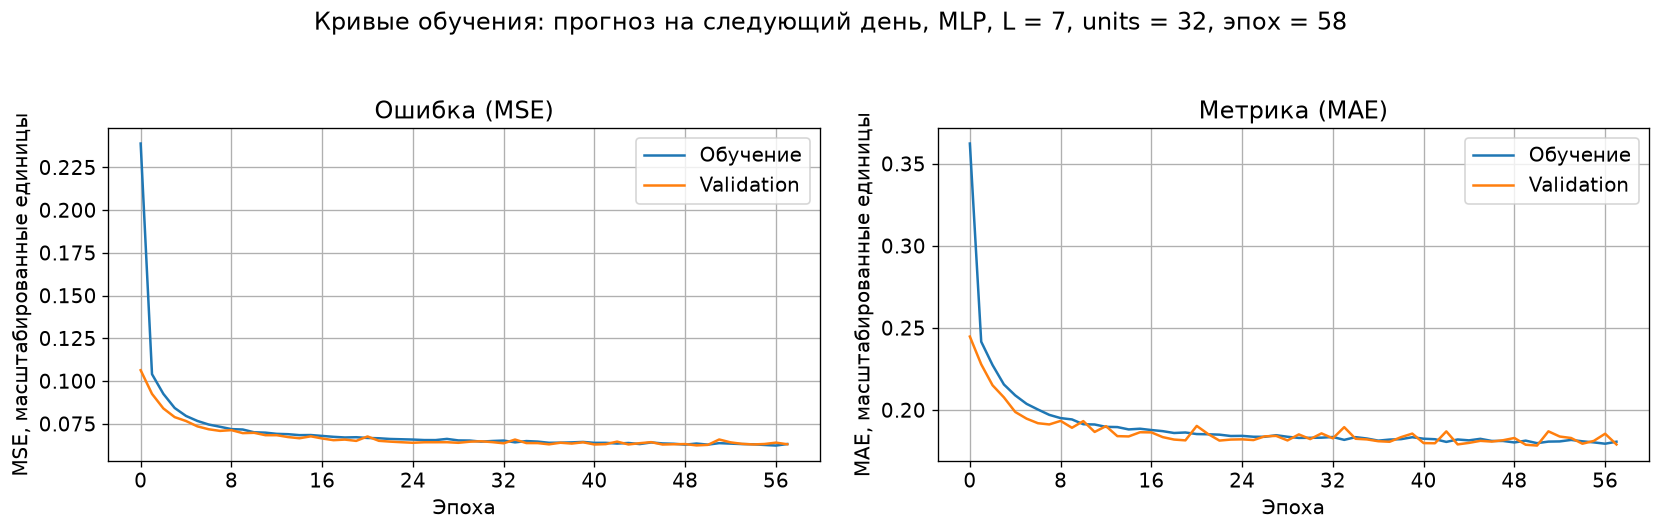

Лучшая эпоха: 50 из 58 , val RMSE = 1.805 °C


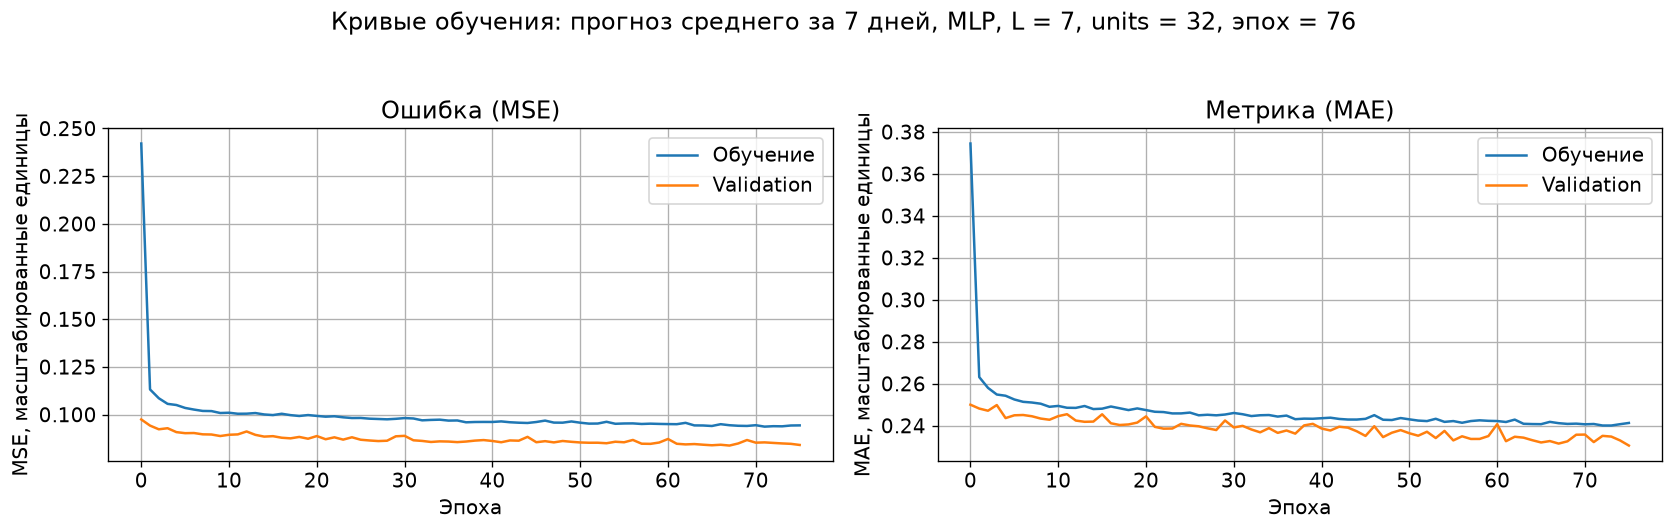

Лучшая эпоха: 68 из 76 , val RMSE = 2.0917 °C


In [21]:
# Кривые обучения лучшей по validation конфигурации архитектуры
current_runs = runs_frame()
for task in TASKS:
    stage = current_runs[(current_runs["task"] == task) & (current_runs["model"] == "MLP")]
    best_record = stage.sort_values("val_RMSE").iloc[0]
    plot_learning_curves(best_record, "lab2-curves-mlp-")

**Результат:** для следующего дня лучшая длина окна - 7 дней: RMSE 1,8050 °C, R2 0,9296. Худший результат при L = 60: RMSE 1,9972 °C. Для недельного среднего лучший результат при L = 7: RMSE 2,0917 °C, R2 0,8973; худший при L = 30: RMSE 2,2594 °C. MLP не использует порядок значений, поэтому длинная история для него - это просто много шумных признаков.

### 2. SimpleRNN: влияние длины окна

SimpleRNN обрабатывает окно по шагам и хранит скрытое состояние. На длинных окнах ожидается затухание градиента, поэтому качество может перестать расти.

In [22]:
# Этап 1, SimpleRNN: 32 ячейки, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "SimpleRNN", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

rnn_stage = runs_frame()
rnn_stage = rnn_stage[(rnn_stage["model"] == "SimpleRNN") & (rnn_stage["units"] == 32)]
display(rnn_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.7863 val R2 = 0.9311


next_day L = 14 val RMSE = 1.7869 val R2 = 0.931


next_day L = 30 val RMSE = 1.8153 val R2 = 0.9288


next_day L = 60 val RMSE = 1.7934 val R2 = 0.9305


weekly_mean L = 7 val RMSE = 2.0937 val R2 = 0.8971


weekly_mean L = 14 val RMSE = 2.0718 val R2 = 0.8992


weekly_mean L = 30 val RMSE = 2.1649 val R2 = 0.8899


weekly_mean L = 60 val RMSE = 1.9804 val R2 = 0.9079


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,8,next_day,SimpleRNN,7,32,adam,0.0,1121,15,7,23.44,1.2794,3.1908,1.7863,0.9311
1,9,next_day,SimpleRNN,14,32,adam,0.0,1121,23,15,50.42,1.2838,3.1930,1.7869,0.9310
2,10,next_day,SimpleRNN,30,32,adam,0.0,1121,16,8,55.53,1.3083,3.2955,1.8153,0.9288
3,11,next_day,SimpleRNN,60,32,adam,0.0,1121,20,12,120.46,1.2791,3.2162,1.7934,0.9305
4,12,weekly_mean,SimpleRNN,7,32,adam,0.0,1121,17,9,26.29,1.6678,4.3837,2.0937,0.8971
5,13,weekly_mean,SimpleRNN,14,32,adam,0.0,1121,24,16,53.11,1.6738,4.2924,2.0718,0.8992
6,14,weekly_mean,SimpleRNN,30,32,adam,0.0,1121,15,7,54.28,1.7168,4.6866,2.1649,0.8899
7,15,weekly_mean,SimpleRNN,60,32,adam,0.0,1121,14,6,86.36,1.6165,3.9220,1.9804,0.9079


#### Кривые обучения SimpleRNN

Для каждой задачи показана лучшая по validation конфигурация SimpleRNN из этого эксперимента. Слева ошибка MSE, справа метрика MAE, обе на обучении и на validation. По кривым видно, за сколько эпох модель выходит на плато и расходится ли validation с обучением, то есть появляется ли переобучение.

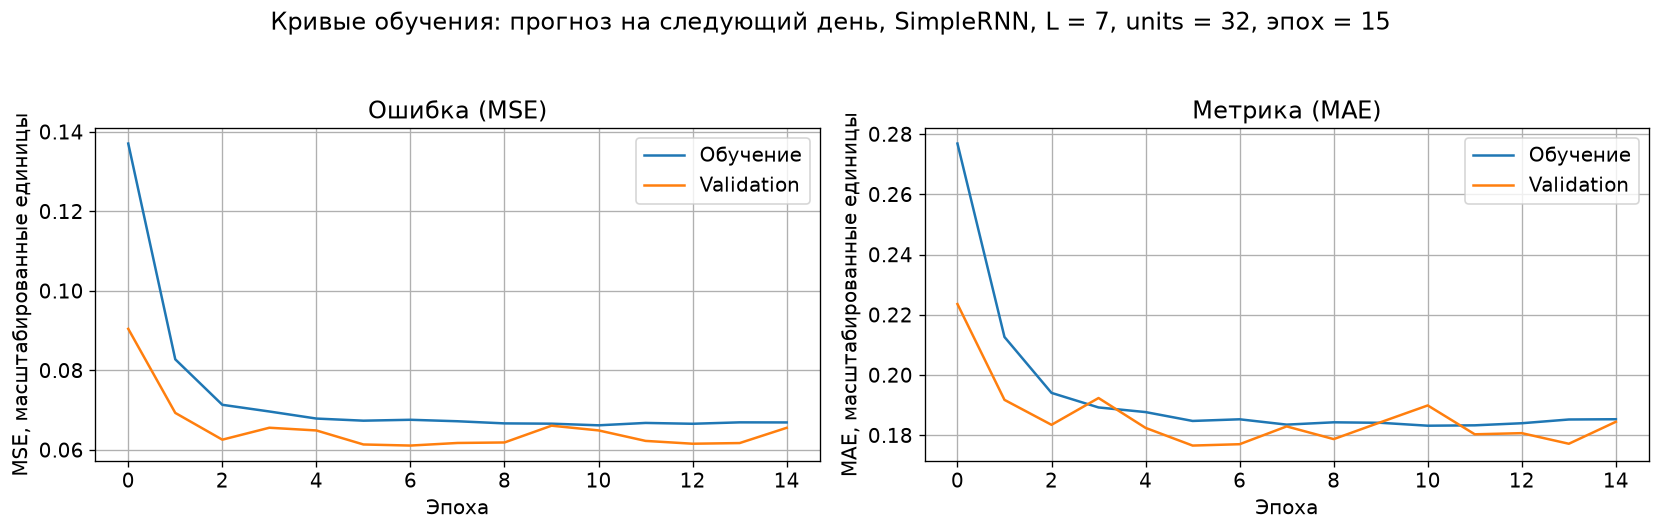

Лучшая эпоха: 7 из 15 , val RMSE = 1.7863 °C


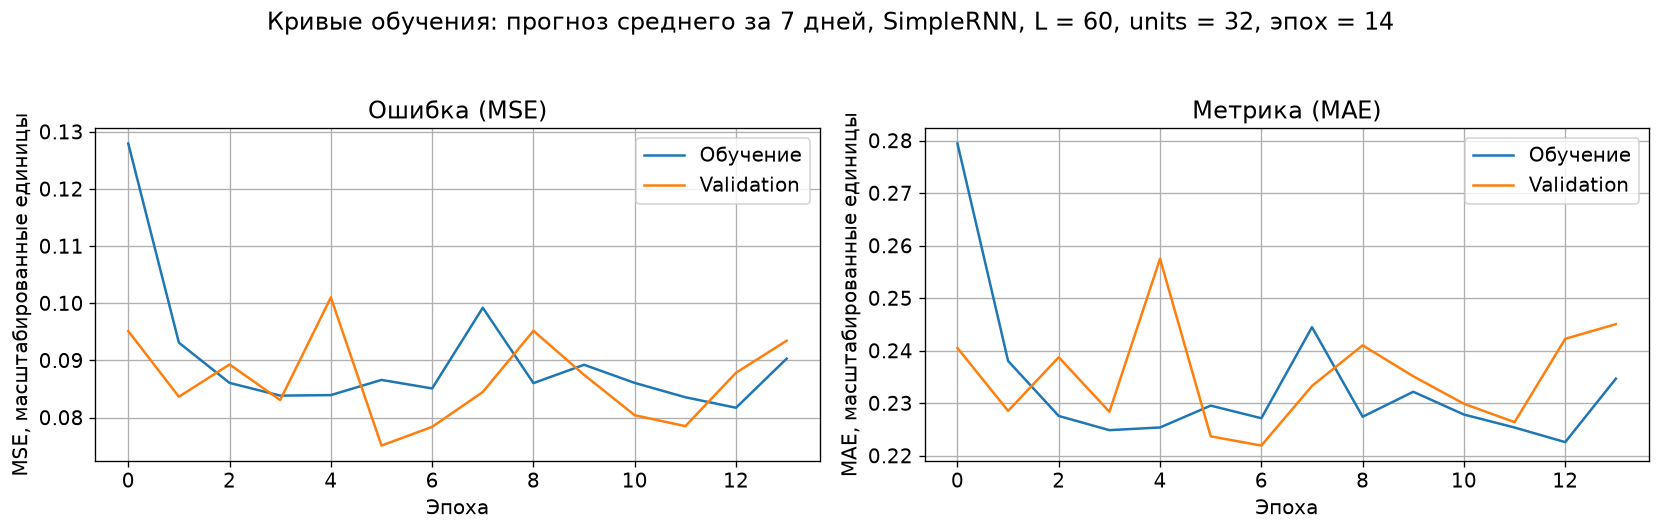

Лучшая эпоха: 6 из 14 , val RMSE = 1.9804 °C


In [23]:
# Кривые обучения лучшей по validation конфигурации архитектуры
current_runs = runs_frame()
for task in TASKS:
    stage = current_runs[(current_runs["task"] == task) & (current_runs["model"] == "SimpleRNN")]
    best_record = stage.sort_values("val_RMSE").iloc[0]
    plot_learning_curves(best_record, "lab2-curves-simplernn-")

**Результат:** SimpleRNN для следующего дня почти не зависит от длины окна: RMSE меняется от 1,7863 до 1,8153 °C, лучшее значение при L = 7 (R2 0,9311). Для недельного среднего длинное окно помогает: лучшее значение при L = 60, RMSE 1,9804 °C и R2 0,9079 против 2,0937 °C при L = 7. Для недельного горизонта нужен более длинный контекст, но затухание градиента не позволяет выигрывать дальше.

### 3. LSTM: влияние длины окна

LSTM использует ворота и отдельную ячейку памяти, поэтому лучше сохраняет долгосрочную информацию. Здесь проверяется, дает ли это преимущество на окнах до 60 дней.

In [24]:
# Этап 1, LSTM: 32 ячейки, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "LSTM", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

lstm_stage = runs_frame()
lstm_stage = lstm_stage[(lstm_stage["model"] == "LSTM") & (lstm_stage["units"] == 32)]
display(lstm_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.7929 val R2 = 0.9306


next_day L = 14 val RMSE = 1.7911 val R2 = 0.9307


next_day L = 30 val RMSE = 1.7928 val R2 = 0.9306


next_day L = 60 val RMSE = 1.7814 val R2 = 0.9315


weekly_mean L = 7 val RMSE = 2.0894 val R2 = 0.8975


weekly_mean L = 14 val RMSE = 2.0703 val R2 = 0.8994


weekly_mean L = 30 val RMSE = 2.1821 val R2 = 0.8882


weekly_mean L = 60 val RMSE = 1.8937 val R2 = 0.9158


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,16,next_day,LSTM,7,32,adam,0.0,4385,45,37,43.90,1.2859,3.2146,1.7929,0.9306
1,17,next_day,LSTM,14,32,adam,0.0,4385,35,27,34.54,1.2823,3.2080,1.7911,0.9307
2,18,next_day,LSTM,30,32,adam,0.0,4385,36,28,35.96,1.2885,3.2142,1.7928,0.9306
3,19,next_day,LSTM,60,32,adam,0.0,4385,44,36,43.84,1.2732,3.1733,1.7814,0.9315
4,20,weekly_mean,LSTM,7,32,adam,0.0,4385,45,37,44.81,1.6831,4.3654,2.0894,0.8975
5,21,weekly_mean,LSTM,14,32,adam,0.0,4385,39,31,39.42,1.6667,4.2860,2.0703,0.8994
6,22,weekly_mean,LSTM,30,32,adam,0.0,4385,16,8,16.13,1.7366,4.7615,2.1821,0.8882
7,23,weekly_mean,LSTM,60,32,adam,0.0,4385,31,23,30.48,1.4849,3.5862,1.8937,0.9158


#### Кривые обучения LSTM

Для каждой задачи показана лучшая по validation конфигурация LSTM из этого эксперимента. Слева ошибка MSE, справа метрика MAE, обе на обучении и на validation. По кривым видно, за сколько эпох модель выходит на плато и расходится ли validation с обучением, то есть появляется ли переобучение.

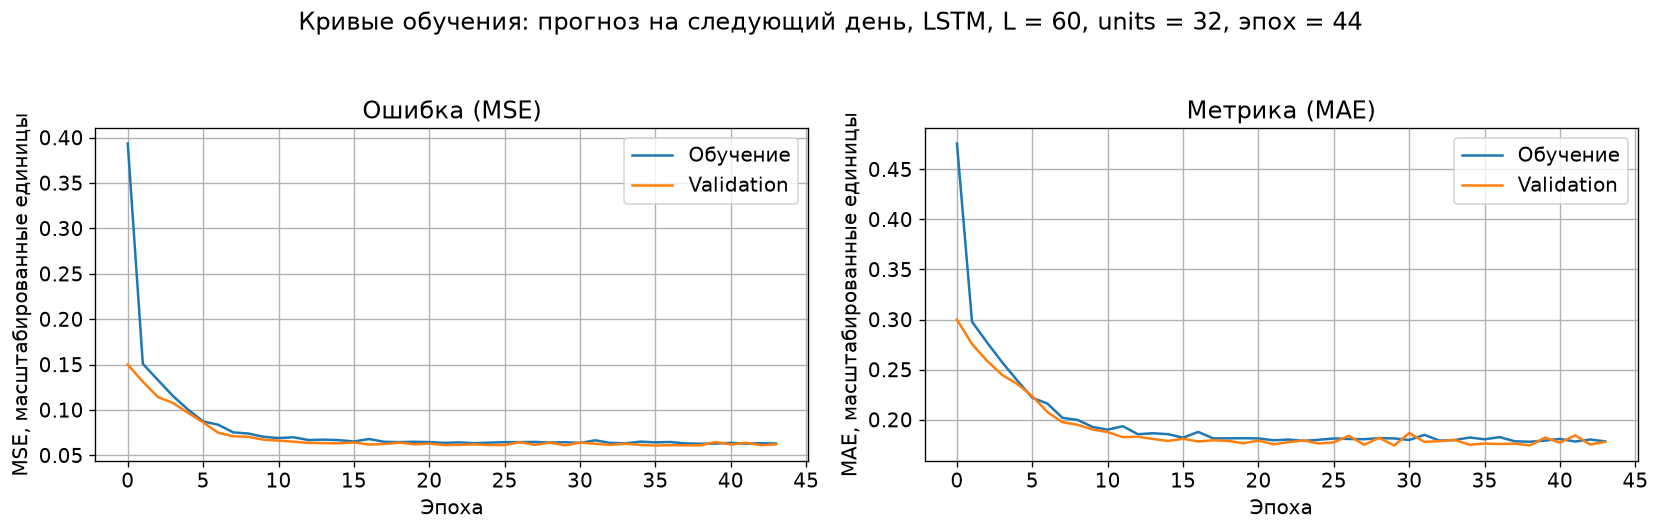

Лучшая эпоха: 36 из 44 , val RMSE = 1.7814 °C


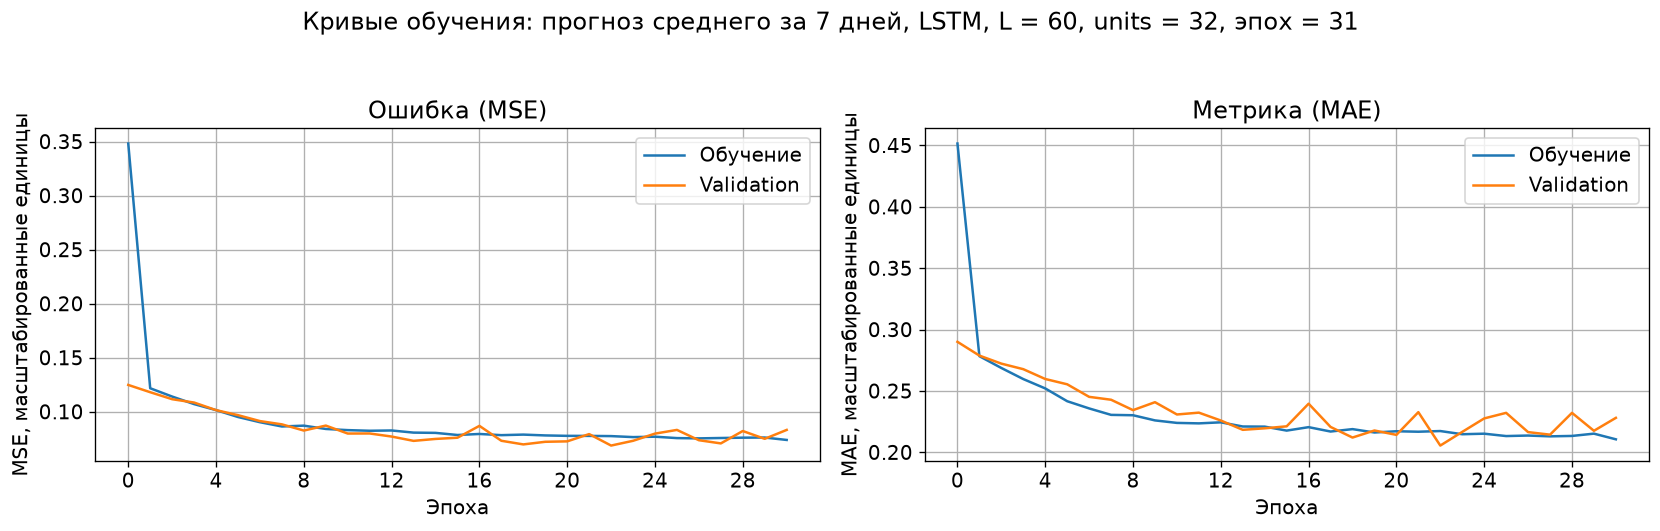

Лучшая эпоха: 23 из 31 , val RMSE = 1.8937 °C


In [25]:
# Кривые обучения лучшей по validation конфигурации архитектуры
current_runs = runs_frame()
for task in TASKS:
    stage = current_runs[(current_runs["task"] == task) & (current_runs["model"] == "LSTM")]
    best_record = stage.sort_values("val_RMSE").iloc[0]
    plot_learning_curves(best_record, "lab2-curves-lstm-")

**Результат:** LSTM для следующего дня дает RMSE от 1,7814 до 1,7929 °C во всем диапазоне окон, лучшее значение при L = 60 (R2 0,9315). Для недельного среднего выигрыш длинного окна выражен сильнее: лучшее значение при L = 60, RMSE 1,8937 °C и R2 0,9158; худшее при L = 30: RMSE 2,1821 °C. LSTM лучше остальных использует длинную историю.

### 4. Stacked LSTM: влияние длины окна

Два последовательных слоя LSTM увеличивают глубину и число параметров. Первый слой возвращает последовательность, второй формирует итоговое представление.

In [26]:
# Этап 1, Stacked LSTM: два слоя по 32 ячейки, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "StackedLSTM", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

stacked_stage = runs_frame()
stacked_stage = stacked_stage[(stacked_stage["model"] == "StackedLSTM") & (stacked_stage["units"] == 32)]
display(stacked_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.7868 val R2 = 0.931


next_day L = 14 val RMSE = 1.793 val R2 = 0.9306


next_day L = 30 val RMSE = 1.7951 val R2 = 0.9304


next_day L = 60 val RMSE = 1.7925 val R2 = 0.9306


weekly_mean L = 7 val RMSE = 2.0876 val R2 = 0.8977


weekly_mean L = 14 val RMSE = 2.0744 val R2 = 0.8989


weekly_mean L = 30 val RMSE = 2.2578 val R2 = 0.8803


weekly_mean L = 60 val RMSE = 2.0892 val R2 = 0.8975


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,24,next_day,StackedLSTM,7,32,adam,0.0,12705,34,26,40.87,1.2862,3.1927,1.7868,0.9310
1,25,next_day,StackedLSTM,14,32,adam,0.0,12705,22,14,26.15,1.2899,3.2149,1.7930,0.9306
2,26,next_day,StackedLSTM,30,32,adam,0.0,12705,23,15,27.15,1.2873,3.2224,1.7951,0.9304
3,27,next_day,StackedLSTM,60,32,adam,0.0,12705,25,17,29.97,1.2713,3.2130,1.7925,0.9306
4,28,weekly_mean,StackedLSTM,7,32,adam,0.0,12705,24,16,28.44,1.6856,4.3579,2.0876,0.8977
5,29,weekly_mean,StackedLSTM,14,32,adam,0.0,12705,32,24,38.79,1.6662,4.3033,2.0744,0.8989
6,30,weekly_mean,StackedLSTM,30,32,adam,0.0,12705,15,7,18.02,1.8195,5.0979,2.2578,0.8803
7,31,weekly_mean,StackedLSTM,60,32,adam,0.0,12705,26,18,31.16,1.7266,4.3649,2.0892,0.8975


#### Кривые обучения Stacked LSTM

Для каждой задачи показана лучшая по validation конфигурация Stacked LSTM из этого эксперимента. Слева ошибка MSE, справа метрика MAE, обе на обучении и на validation. По кривым видно, за сколько эпох модель выходит на плато и расходится ли validation с обучением, то есть появляется ли переобучение.

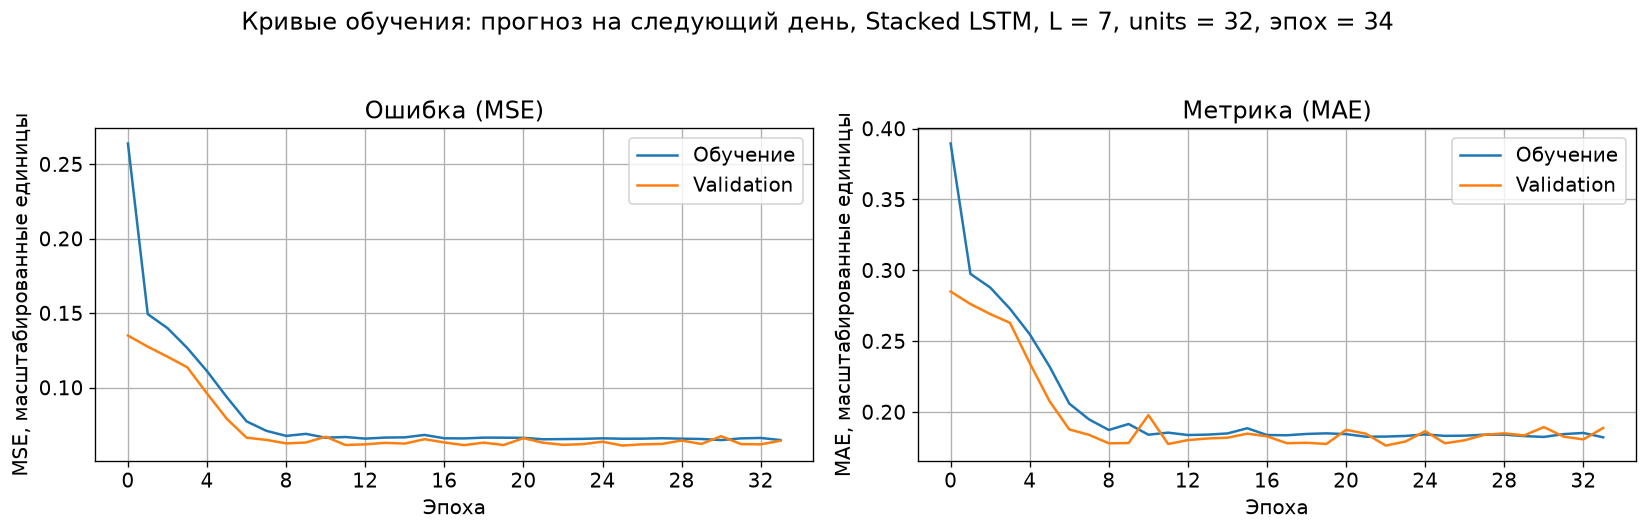

Лучшая эпоха: 26 из 34 , val RMSE = 1.7868 °C


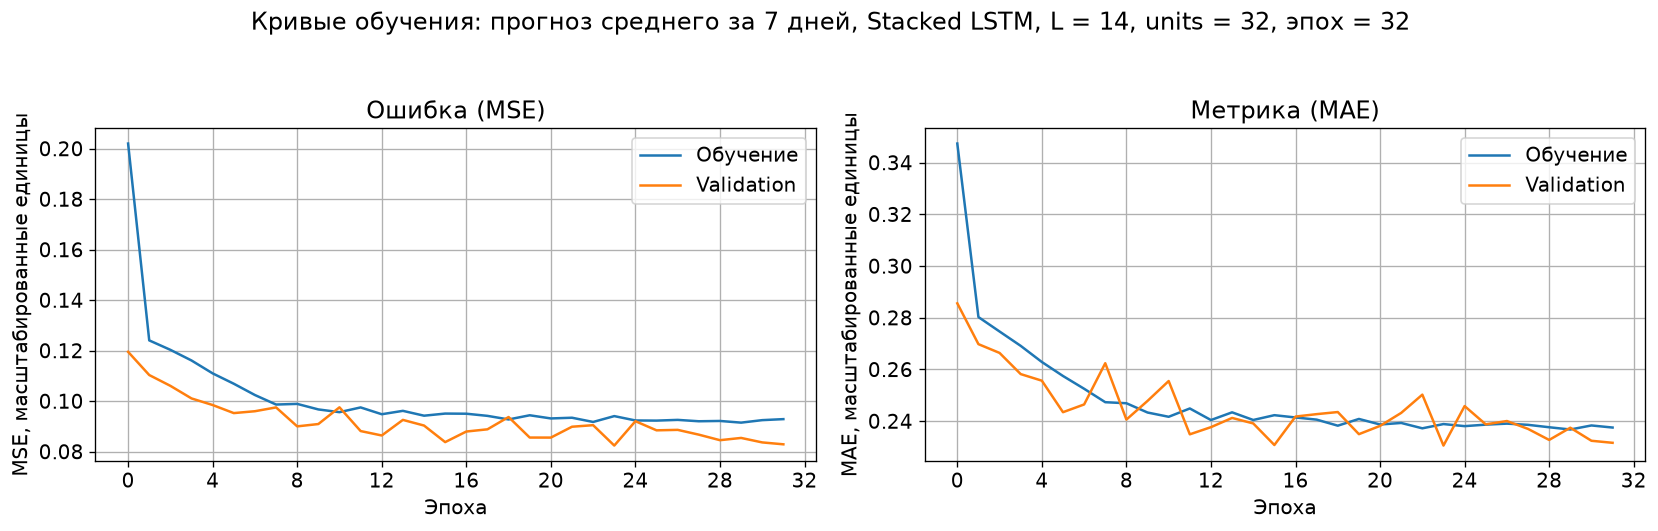

Лучшая эпоха: 24 из 32 , val RMSE = 2.0744 °C


In [27]:
# Кривые обучения лучшей по validation конфигурации архитектуры
current_runs = runs_frame()
for task in TASKS:
    stage = current_runs[(current_runs["task"] == task) & (current_runs["model"] == "StackedLSTM")]
    best_record = stage.sort_values("val_RMSE").iloc[0]
    plot_learning_curves(best_record, "lab2-curves-stackedlstm-")

**Результат:** двухслойная LSTM для следующего дня показывает RMSE от 1,7868 до 1,7951 °C, лучший результат при L = 7 (R2 0,9310). Для недельного среднего лучшее значение при L = 14: RMSE 2,0744 °C, R2 0,8989; худшее при L = 30: RMSE 2,2578 °C. Второй рекуррентный слой не дал устойчивого выигрыша по сравнению с однослойной LSTM и увеличил число параметров до 12 705.

### 5. Влияние числа нейронов и ячеек

Для каждой архитектуры и каждой задачи выбирается лучшая длина окна по validation RMSE, затем та же конфигурация обучается с 64 нейронами или ячейками. Сравнение показывает, дает ли увеличение емкости выигрыш или приводит к переобучению.

In [28]:
# Этап 2: для лучшей длины окна увеличиваем число нейронов до 64
stage1 = runs_frame()
stage1 = stage1[stage1["units"] == 32]
best_window = (
    stage1.sort_values("val_RMSE")
    .groupby(["task", "model"], as_index=False)
    .head(1)[["task", "model", "window", "units", "val_RMSE"]]
)
display(best_window.sort_values(["task", "model"]).reset_index(drop=True))

for _, row in best_window.iterrows():
    record = run_experiment(
        row["task"],
        row["model"],
        int(row["window"]),
        units=64,
    )
    print(
        row["task"], row["model"], "L =", int(row["window"]),
        "units = 64, val RMSE =", round(record["val_RMSE"], 4),
    )

units_stage = runs_frame()
units_stage = units_stage[units_stage["units"] == 64]
display(units_stage.sort_values(["task", "val_RMSE"]).reset_index(drop=True))

,task,model,window,units,val_RMSE
0,next_day,LSTM,60,32,1.7814
1,next_day,MLP,7,32,1.8050
2,next_day,SimpleRNN,7,32,1.7863
3,next_day,StackedLSTM,7,32,1.7868
4,weekly_mean,LSTM,60,32,1.8937
5,weekly_mean,MLP,7,32,2.0917
6,weekly_mean,SimpleRNN,60,32,1.9804
7,weekly_mean,StackedLSTM,14,32,2.0744


next_day LSTM L = 60 units = 64, val RMSE = 1.7959


next_day SimpleRNN L = 7 units = 64, val RMSE = 1.7934


next_day StackedLSTM L = 7 units = 64, val RMSE = 1.7916


next_day MLP L = 7 units = 64, val RMSE = 1.7567


weekly_mean LSTM L = 60 units = 64, val RMSE = 2.0008


weekly_mean SimpleRNN L = 60 units = 64, val RMSE = 2.0369


weekly_mean StackedLSTM L = 14 units = 64, val RMSE = 2.0879


weekly_mean MLP L = 7 units = 64, val RMSE = 2.1022


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,35,next_day,MLP,7,64,adam,0.0,577,38,30,30.39,1.2570,3.0862,1.7567,0.9333
1,34,next_day,StackedLSTM,7,64,adam,0.0,49985,23,15,27.68,1.2853,3.2097,1.7916,0.9307
2,33,next_day,SimpleRNN,7,64,adam,0.0,4289,14,6,21.79,1.2817,3.2164,1.7934,0.9305
3,32,next_day,LSTM,60,64,adam,0.0,16961,25,17,24.63,1.2727,3.2251,1.7959,0.9303
4,36,weekly_mean,LSTM,60,64,adam,0.0,16961,26,18,24.98,1.6265,4.0032,2.0008,0.9060
5,37,weekly_mean,SimpleRNN,60,64,adam,0.0,4289,18,10,109.85,1.6365,4.1488,2.0369,0.9026
6,38,weekly_mean,StackedLSTM,14,64,adam,0.0,49985,24,16,28.65,1.6743,4.3594,2.0879,0.8976
7,39,weekly_mean,MLP,7,64,adam,0.0,577,36,28,28.73,1.6970,4.4191,2.1022,0.8962


#### Кривые обучения: число нейронов

Для каждой задачи и каждой архитектуры показана пара: лучшая конфигурация с 32 нейронами или ячейками и та же конфигурация с 64. Слева MSE, справа MAE; сплошная линия - обучение, пунктир - validation. Если validation перестает снижаться и уходит вверх, а обучение продолжает падать, рост емкости ведет к переобучению.

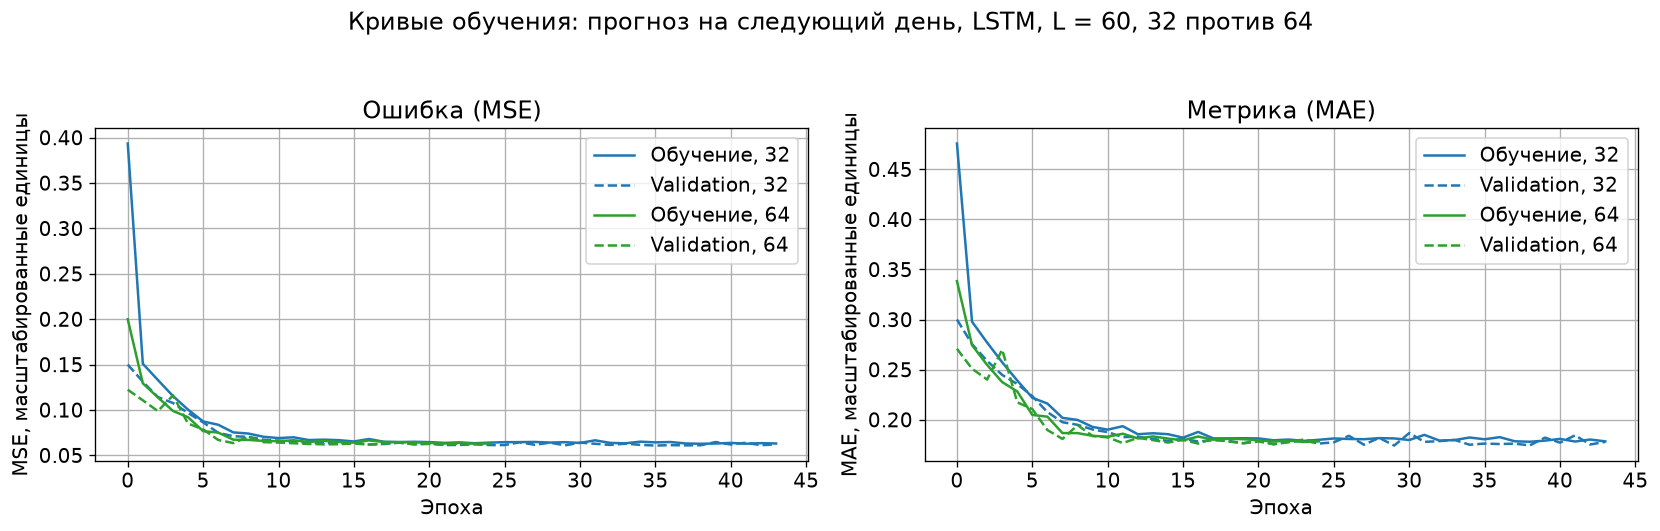

32 - лучшая эпоха 36 из 44 , val RMSE = 1.7814 °C
64 - лучшая эпоха 17 из 25 , val RMSE = 1.7959 °C


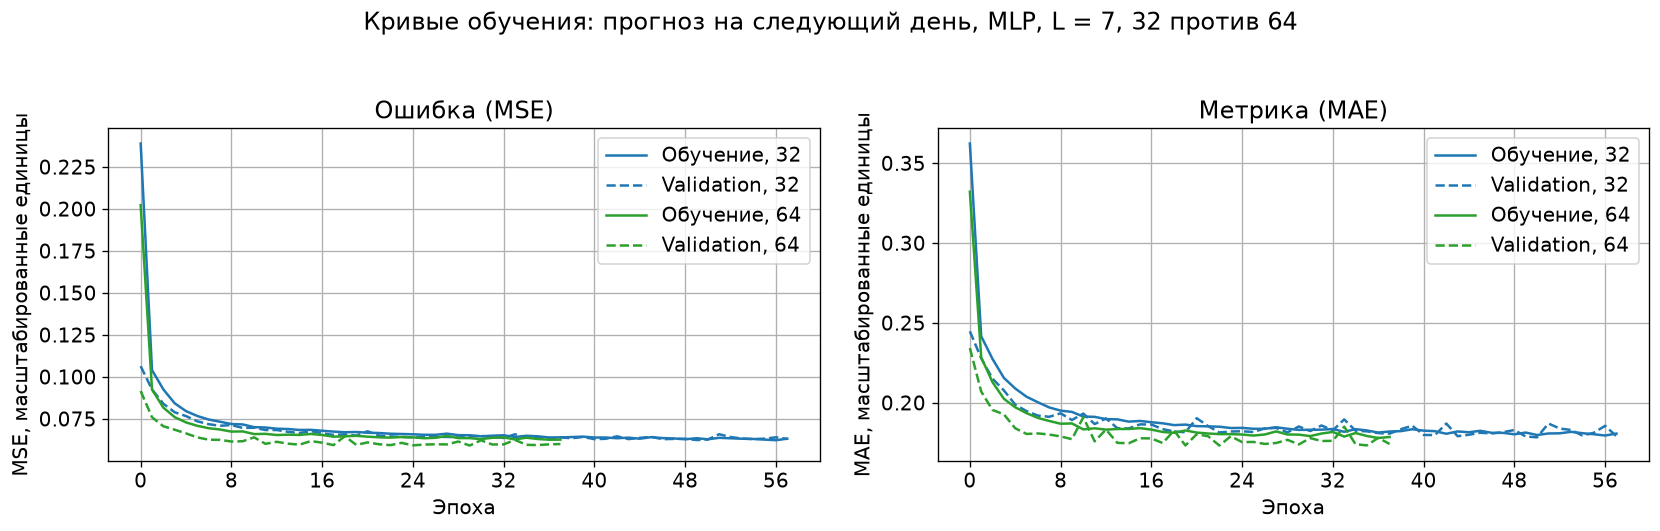

32 - лучшая эпоха 50 из 58 , val RMSE = 1.805 °C
64 - лучшая эпоха 30 из 38 , val RMSE = 1.7567 °C


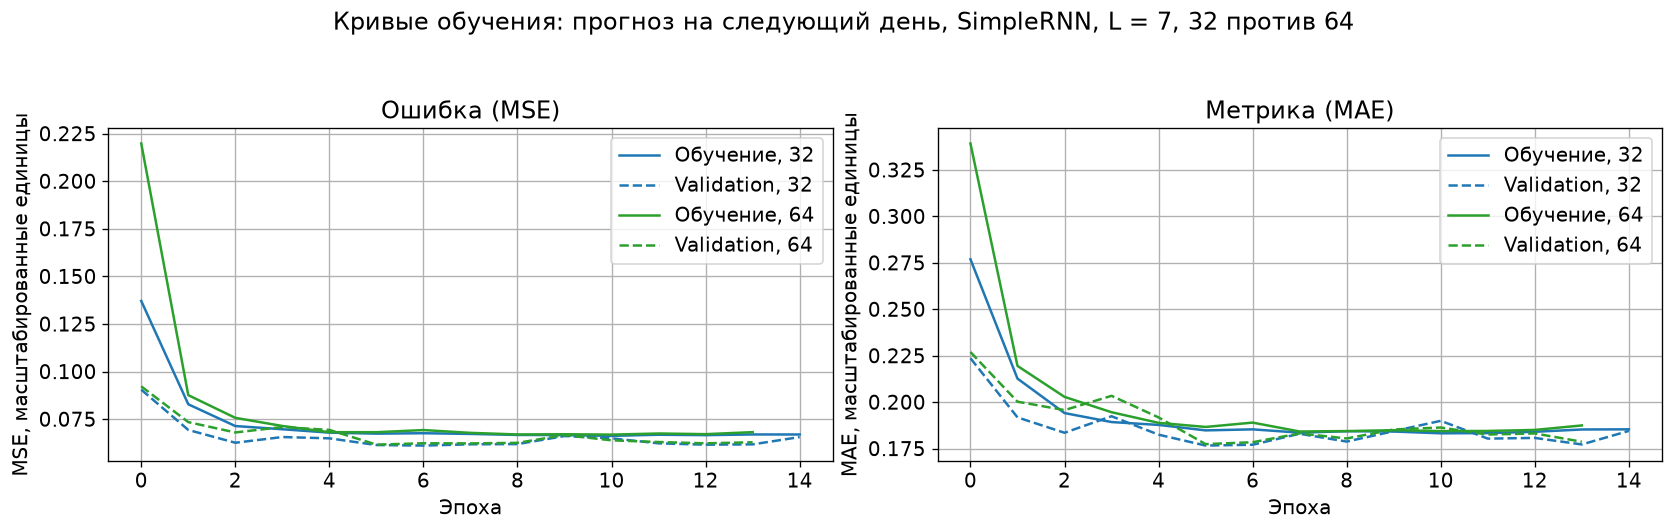

32 - лучшая эпоха 7 из 15 , val RMSE = 1.7863 °C
64 - лучшая эпоха 6 из 14 , val RMSE = 1.7934 °C


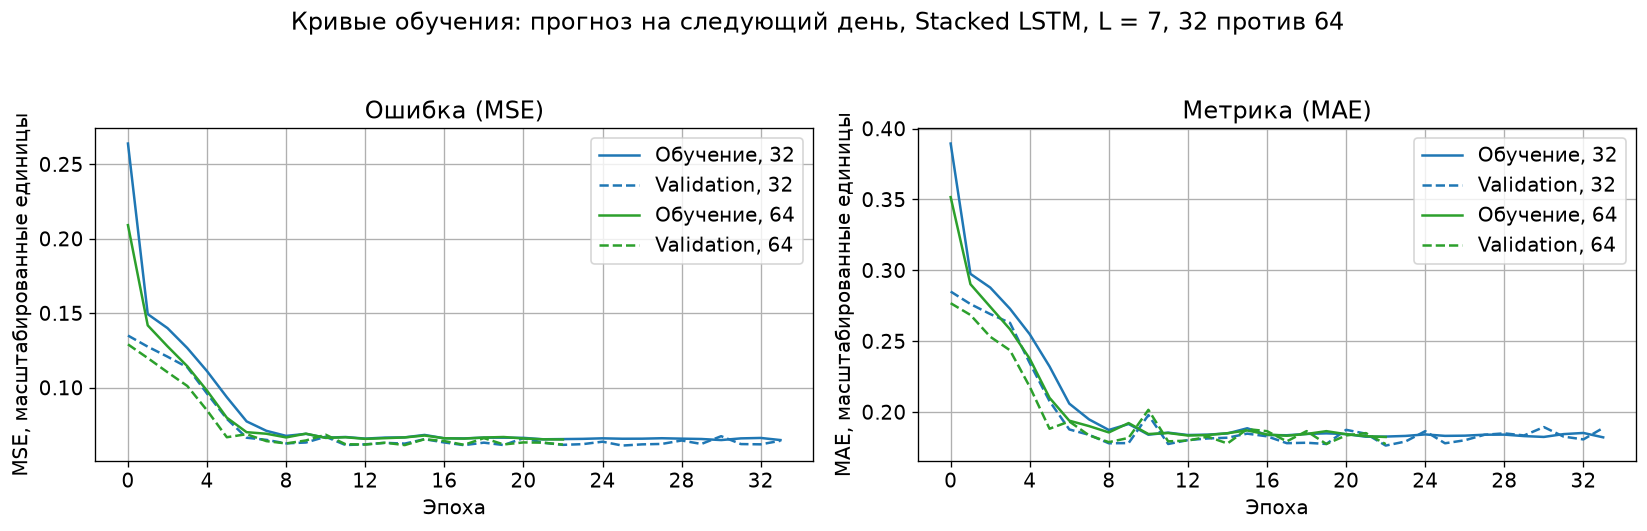

32 - лучшая эпоха 26 из 34 , val RMSE = 1.7868 °C
64 - лучшая эпоха 15 из 23 , val RMSE = 1.7916 °C


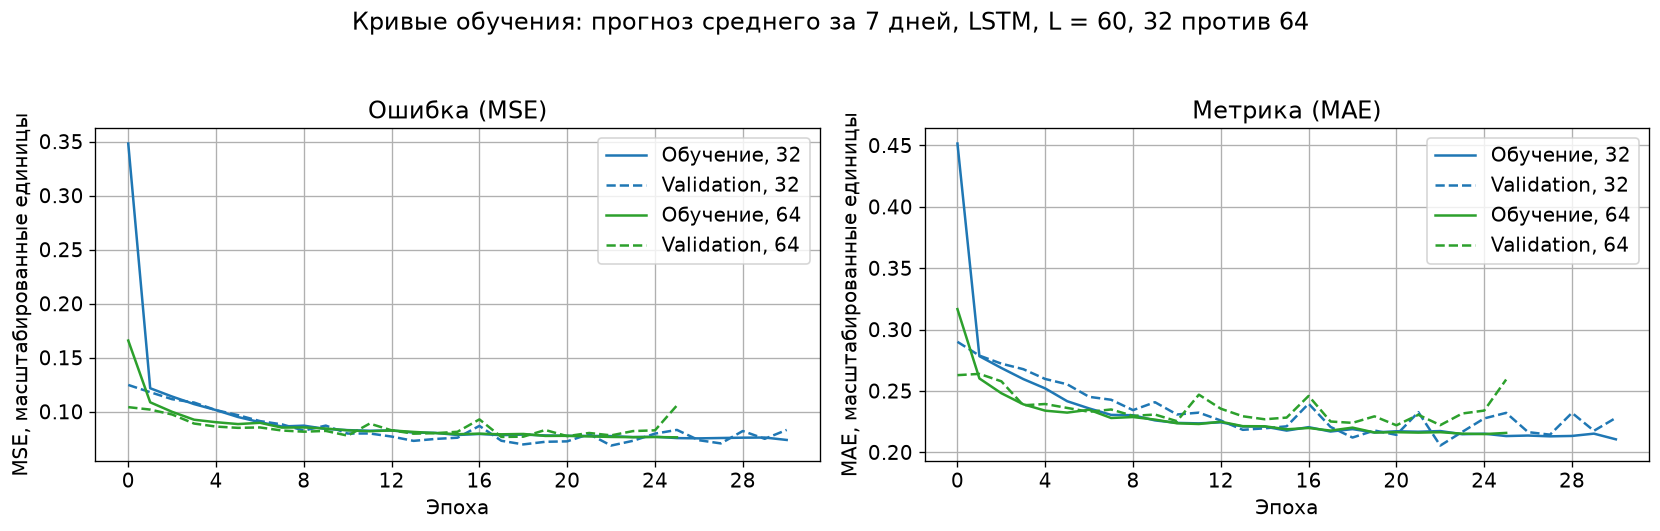

32 - лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C
64 - лучшая эпоха 18 из 26 , val RMSE = 2.0008 °C


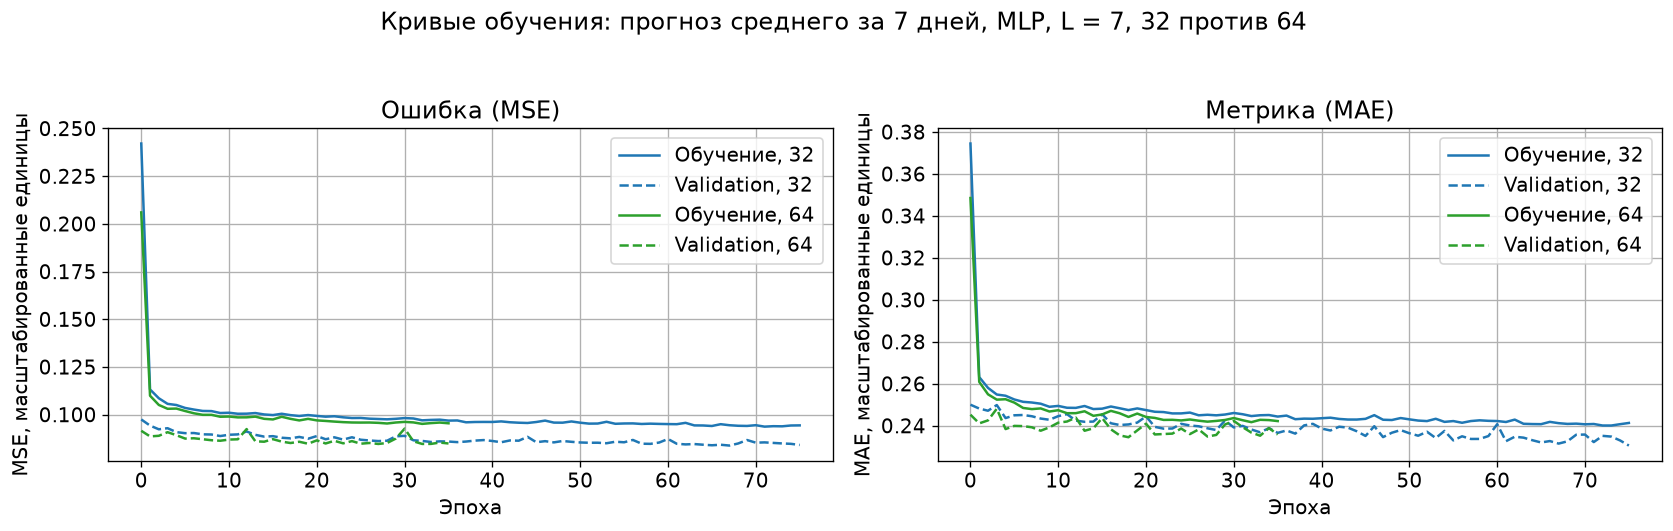

32 - лучшая эпоха 68 из 76 , val RMSE = 2.0917 °C
64 - лучшая эпоха 28 из 36 , val RMSE = 2.1022 °C


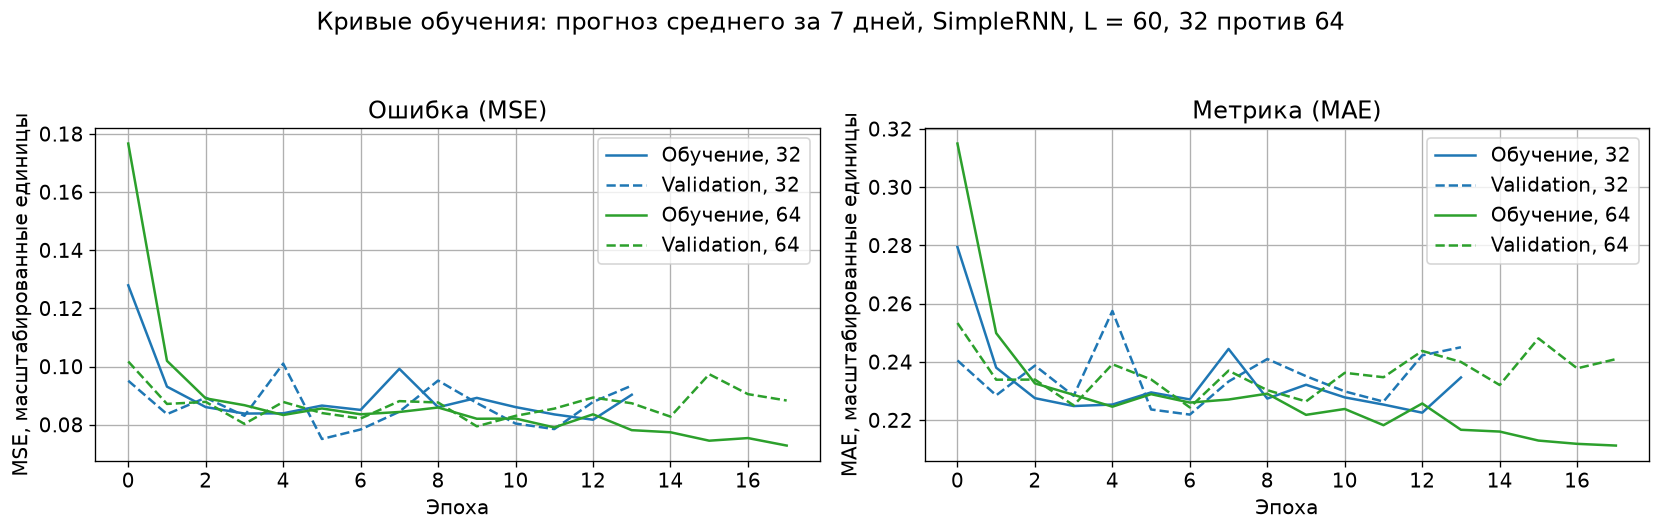

32 - лучшая эпоха 6 из 14 , val RMSE = 1.9804 °C
64 - лучшая эпоха 10 из 18 , val RMSE = 2.0369 °C


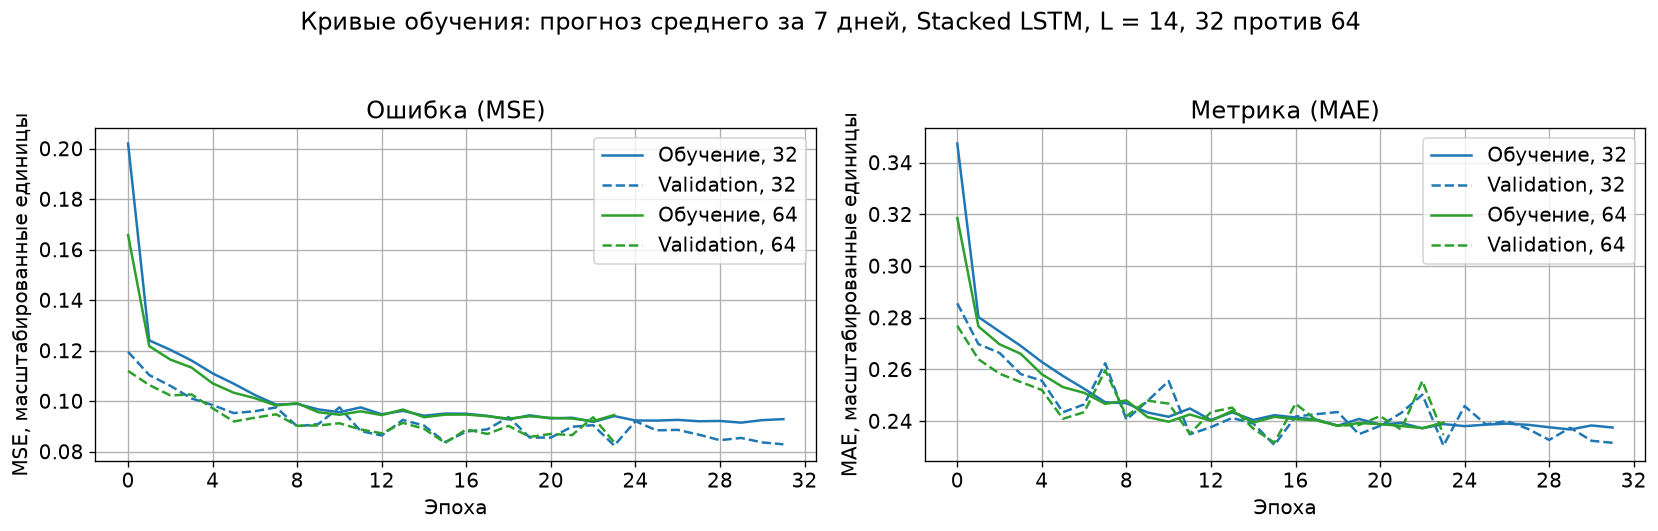

32 - лучшая эпоха 24 из 32 , val RMSE = 2.0744 °C
64 - лучшая эпоха 16 из 24 , val RMSE = 2.0879 °C


In [29]:
# Кривые обучения: конфигурация с 32 нейронами и та же с 64
all_runs = runs_frame()
units_runs = all_runs[all_runs["units"] == 64]

for _, record in units_runs.sort_values(["task", "model"]).iterrows():
    # Базовая конфигурация: те же задача, модель, окно, оптимизатор и Dropout, но 32 нейрона
    same_config = (
        (all_runs["task"] == record["task"])
        & (all_runs["model"] == record["model"])
        & (all_runs["window"] == record["window"])
        & (all_runs["units"] == 32)
        & (all_runs["optimizer"] == record["optimizer"])
        & (all_runs["dropout"] == record["dropout"])
    )
    base_runs = all_runs[same_config]
    if base_runs.empty:
        continue
    base_record = base_runs.sort_values("val_RMSE").iloc[0]

    title = (
        TASK_TITLES[record["task"]] + ", " + MODEL_TITLES[record["model"]]
        + ", L = " + str(int(record["window"])) + ", 32 против 64"
    )
    plot_learning_curves(
        record,
        "lab2-curves-units-" + record["model"].lower() + "-",
        base_record=base_record,
        base_label="32",
        record_label="64",
        title=title,
    )

**Результат:** увеличение до 64 нейронов помогло MLP в задаче на следующий день: RMSE 1,8050 -> 1,7567 °C. У остальных конфигураций рост емкости ухудшил validation RMSE, например: SimpleRNN в задаче на следующий день: 1,7863 -> 1,7934 °C; LSTM в задаче на следующий день: 1,7814 -> 1,7959 °C; Stacked LSTM в задаче на следующий день: 1,7868 -> 1,7916 °C; MLP в задаче на недельное среднее: 2,0917 -> 2,1022 °C. Для большинства моделей 32 нейрона или ячейки достаточно, лишняя емкость приводит к переобучению.

### 6. Сравнение оптимизаторов

Для лучшей конфигурации каждой задачи, выбранной по validation, обучение повторяется с RMSprop. Остальные параметры не меняются, чтобы разница отражала только оптимизатор.

In [30]:
# Этап 3: проверяем RMSprop вместо Adam для лучших конфигураций
current = runs_frame()
best_config = (
    current.sort_values("val_RMSE")
    .groupby("task", as_index=False)
    .head(1)[["task", "model", "window", "units", "optimizer", "dropout", "val_RMSE"]]
)
display(best_config.reset_index(drop=True))

for _, row in best_config.iterrows():
    if row["optimizer"] == "rmsprop":
        print(row["task"], "лучшая конфигурация уже использует RMSprop, повтор не нужен")
        continue
    record = run_experiment(
        row["task"],
        row["model"],
        int(row["window"]),
        int(row["units"]),
        optimizer_name="rmsprop",
        dropout=float(row["dropout"]),
    )
    print(
        row["task"], row["model"], "L =", int(row["window"]),
        "units =", int(row["units"]), "RMSprop, val RMSE =", round(record["val_RMSE"], 4),
    )

optimizer_stage = runs_frame()
optimizer_stage = optimizer_stage[
    (optimizer_stage["window"].isin(best_config["window"]))
    & (optimizer_stage["units"].isin(best_config["units"]))
]
display(optimizer_stage.sort_values(["task", "optimizer"]).reset_index(drop=True))

,task,model,window,units,optimizer,dropout,val_RMSE
0,next_day,MLP,7,64,adam,0.0,1.7567
1,weekly_mean,LSTM,60,32,adam,0.0,1.8937


next_day MLP L = 7 units = 64 RMSprop, val RMSE = 1.7601


weekly_mean LSTM L = 60 units = 32 RMSprop, val RMSE = 1.9293


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,0,next_day,MLP,7,32,adam,0.0,289,58,50,43.32,1.2928,3.2579,1.8050,0.9296
1,3,next_day,MLP,60,32,adam,0.0,1985,53,45,41.98,1.4503,3.9887,1.9972,0.9139
2,8,next_day,SimpleRNN,7,32,adam,0.0,1121,15,7,23.44,1.2794,3.1908,1.7863,0.9311
3,11,next_day,SimpleRNN,60,32,adam,0.0,1121,20,12,120.46,1.2791,3.2162,1.7934,0.9305
4,16,next_day,LSTM,7,32,adam,0.0,4385,45,37,43.90,1.2859,3.2146,1.7929,0.9306
5,19,next_day,LSTM,60,32,adam,0.0,4385,44,36,43.84,1.2732,3.1733,1.7814,0.9315
6,24,next_day,StackedLSTM,7,32,adam,0.0,12705,34,26,40.87,1.2862,3.1927,1.7868,0.9310
7,27,next_day,StackedLSTM,60,32,adam,0.0,12705,25,17,29.97,1.2713,3.2130,1.7925,0.9306
8,32,next_day,LSTM,60,64,adam,0.0,16961,25,17,24.63,1.2727,3.2251,1.7959,0.9303
9,33,next_day,SimpleRNN,7,64,adam,0.0,4289,14,6,21.79,1.2817,3.2164,1.7934,0.9305


#### Кривые обучения: оптимизаторы

Для лучшей конфигурации каждой задачи на одних осях показаны Adam и RMSprop. Сплошная линия - обучение, пунктир - validation. По кривым видно, какой оптимизатор быстрее снижает ошибку и насколько устойчиво ведет себя validation.

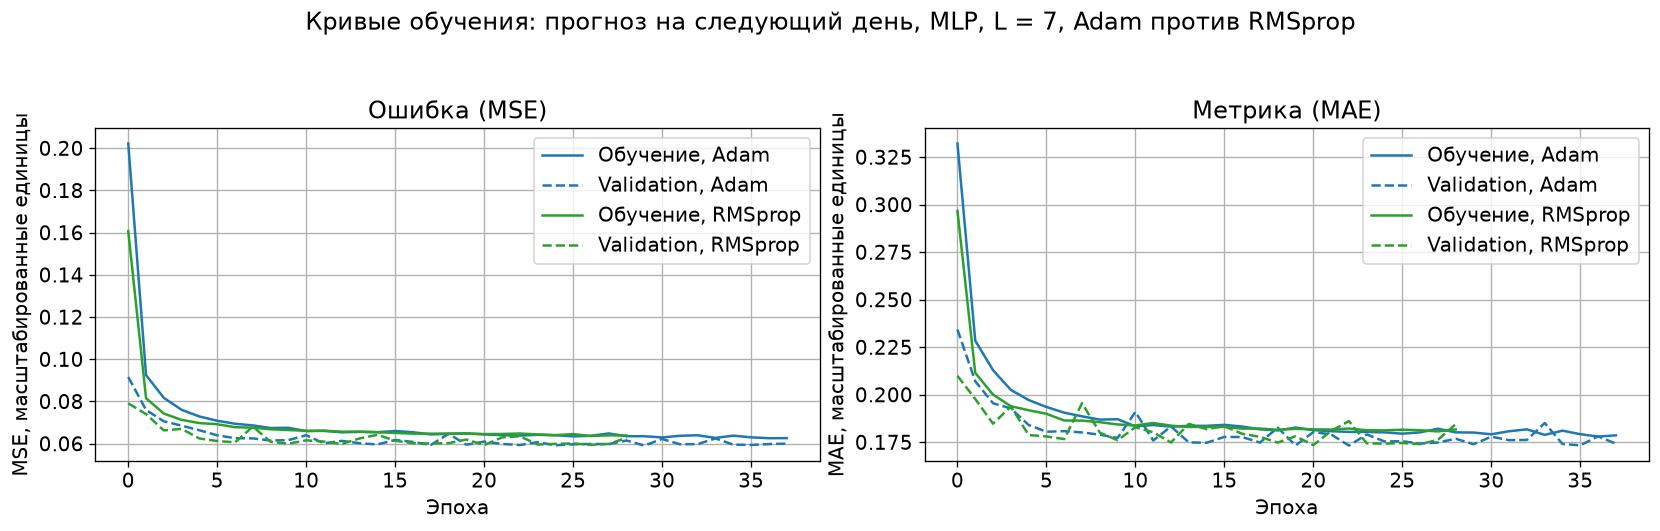

Adam - лучшая эпоха 30 из 38 , val RMSE = 1.7567 °C
RMSprop - лучшая эпоха 21 из 29 , val RMSE = 1.7601 °C


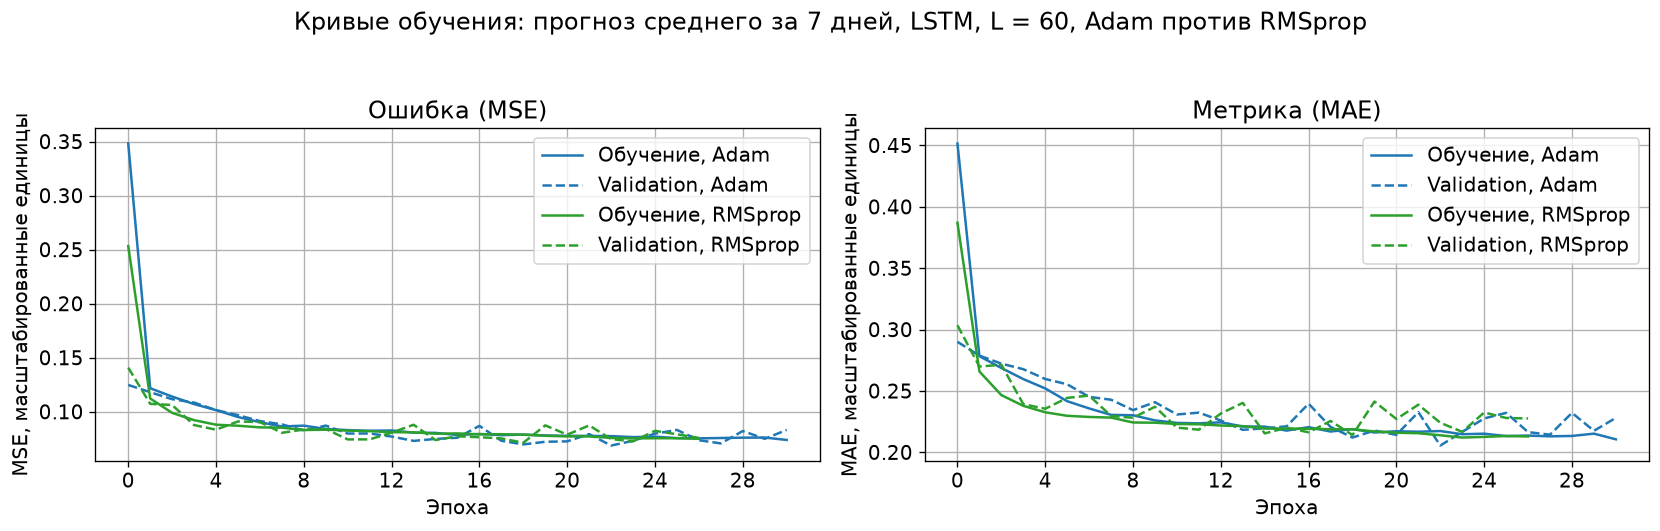

Adam - лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C
RMSprop - лучшая эпоха 19 из 27 , val RMSE = 1.9293 °C


In [31]:
# Кривые обучения: Adam и RMSprop для лучшей конфигурации каждой задачи
all_runs = runs_frame()

for _, row in best_config.iterrows():
    # Остальные параметры совпадают, отличается только оптимизатор
    same_config = (
        (all_runs["task"] == row["task"])
        & (all_runs["model"] == row["model"])
        & (all_runs["window"] == row["window"])
        & (all_runs["units"] == row["units"])
        & (all_runs["dropout"] == row["dropout"])
    )
    adam_run = all_runs[same_config & (all_runs["optimizer"] == "adam")].sort_values("val_RMSE").iloc[0]
    rmsprop_run = all_runs[same_config & (all_runs["optimizer"] == "rmsprop")].sort_values("val_RMSE").iloc[0]

    title = (
        TASK_TITLES[row["task"]] + ", " + MODEL_TITLES[row["model"]]
        + ", L = " + str(int(row["window"])) + ", Adam против RMSprop"
    )
    plot_learning_curves(
        rmsprop_run,
        "lab2-curves-optimizer-",
        base_record=adam_run,
        base_label="Adam",
        record_label="RMSprop",
        title=title,
    )

**Результат:** Adam оказался лучше RMSprop в обеих задачах: MLP на следующий день - RMSE 1,7567 против 1,7601 °C; LSTM на недельное среднее - RMSE 1,8937 против 1,9293 °C. Разница небольшая, но при одинаковых остальных параметрах Adam стабильнее, поэтому он оставлен основным оптимизатором.

### 7. Эксперимент с Dropout

Dropout добавляется после рекуррентного слоя или после Dense-слоя в MLP. Сначала модель обучалась без регуляризации, поэтому по кривым обучения видно, было ли переобучение. Этот эксперимент проверяет, помогает ли Dropout 0,2 лучшей конфигурации каждой задачи.

In [32]:
# Этап 4: проверяем Dropout 0.2 для лучших конфигураций
current = runs_frame()
best_config = (
    current.sort_values("val_RMSE")
    .groupby("task", as_index=False)
    .head(1)[["task", "model", "window", "units", "optimizer", "dropout", "val_RMSE"]]
)

for _, row in best_config.iterrows():
    record = run_experiment(
        row["task"],
        row["model"],
        int(row["window"]),
        int(row["units"]),
        optimizer_name=row["optimizer"],
        dropout=0.2,
    )
    print(
        row["task"], row["model"], "L =", int(row["window"]),
        "units =", int(row["units"]), "Dropout = 0.2, val RMSE =", round(record["val_RMSE"], 4),
    )

dropout_stage = runs_frame()
dropout_stage = dropout_stage[dropout_stage["dropout"] > 0]
display(dropout_stage.sort_values(["task", "val_RMSE"]).reset_index(drop=True))

next_day MLP L = 7 units = 64 Dropout = 0.2, val RMSE = 1.7766


weekly_mean LSTM L = 60 units = 32 Dropout = 0.2, val RMSE = 2.0129


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,42,next_day,MLP,7,64,adam,0.2,577,31,23,23.82,1.2873,3.1564,1.7766,0.9318
1,43,weekly_mean,LSTM,60,32,adam,0.2,4385,27,19,25.47,1.6334,4.0518,2.0129,0.9049


In [33]:
# Сохраняем все прогоны, чтобы числа в отчете можно было проверить
runs_frame().to_csv(RESULTS_DIR / "lab2-runs.csv", index=False, encoding="utf-8")
print("Сохранено прогонов:", len(runs))

Сохранено прогонов: 44


**Результат:** Dropout 0,2 ухудшил validation RMSE в обеих задачах: MLP на следующий день - 1,7567 -> 1,7766 °C; LSTM на недельное среднее - 1,8937 -> 2,0129 °C. По кривым обучения переобучения не было: validation loss не рос после минимума и был близок к train loss. Значит, регуляризация в этой задаче не нужна, и в итоговых моделях Dropout не используется.

#### Кривые обучения до и после Dropout

Сравниваем историю обучения лучшей конфигурации без регуляризации и той же конфигурации с Dropout 0,2: по кривым train/validation loss видно, изменился ли разрыв и появились ли признаки переобучения.

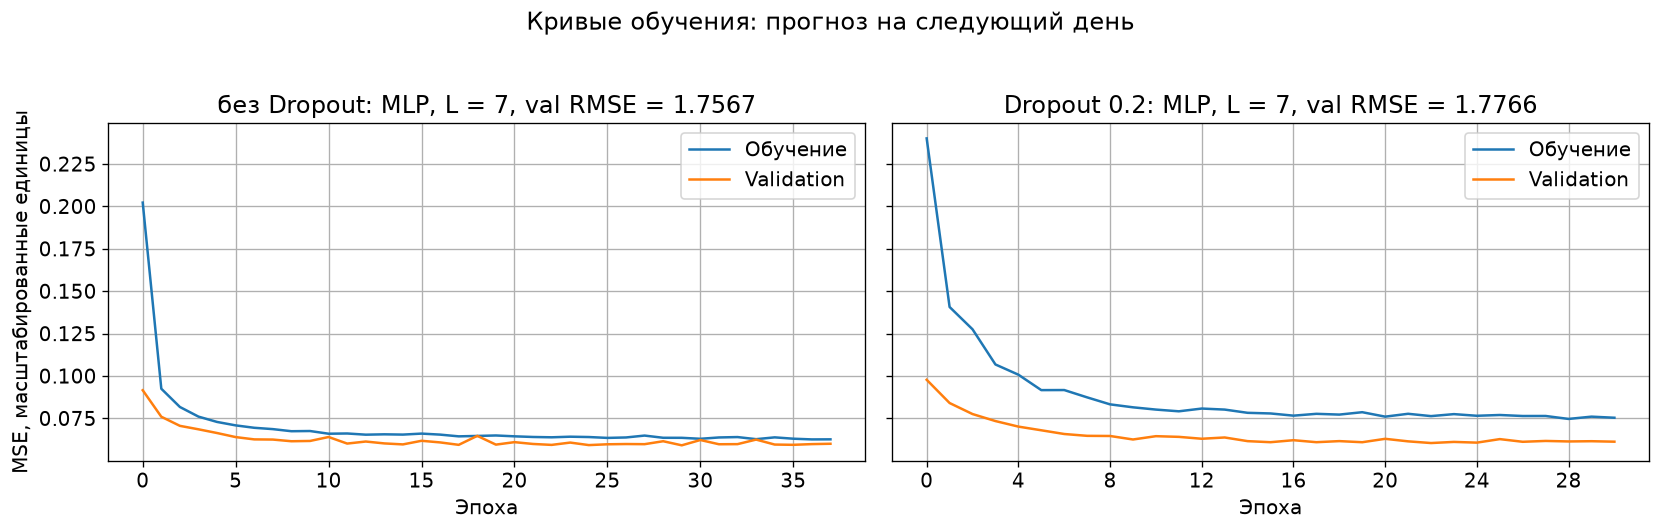

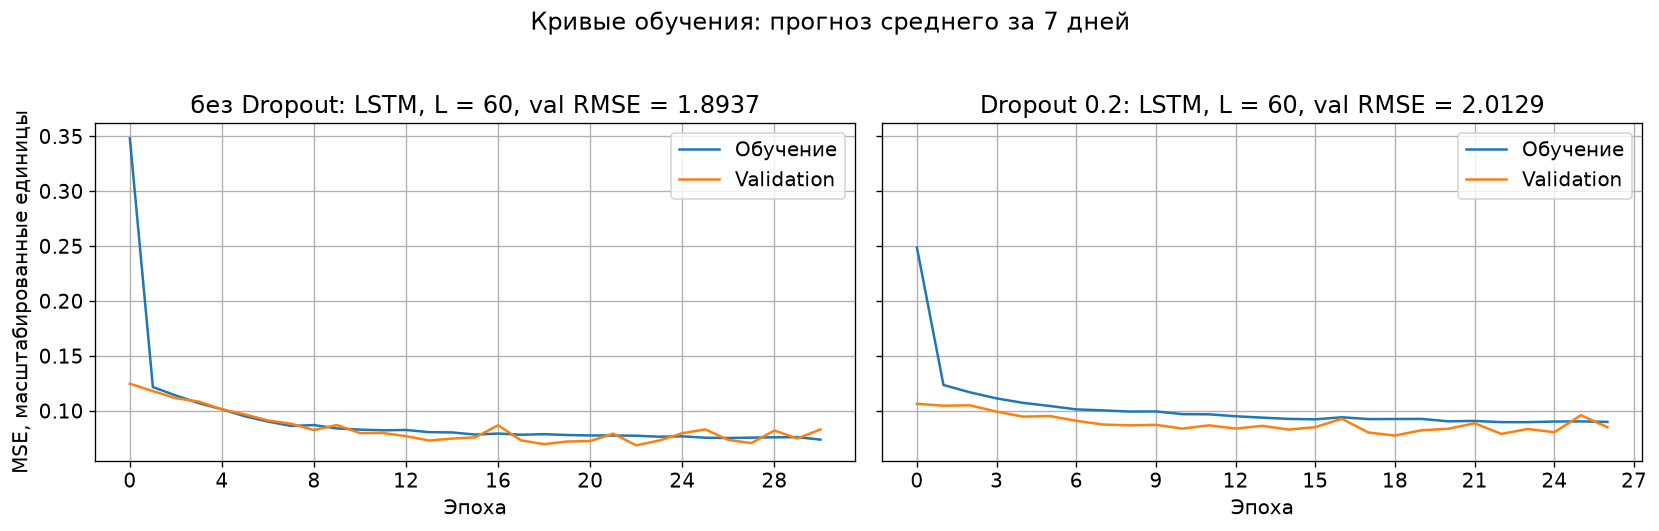

In [34]:
# Сравнение кривых обучения без Dropout и с Dropout 0.2
from matplotlib.ticker import MaxNLocator

all_runs = runs_frame()
dropout_runs = all_runs[all_runs["dropout"] > 0]

for task in TASKS:
    drop = dropout_runs[dropout_runs["task"] == task].sort_values("val_RMSE").iloc[0]
    base = all_runs[
        (all_runs["task"] == task)
        & (all_runs["model"] == drop["model"])
        & (all_runs["window"] == drop["window"])
        & (all_runs["units"] == drop["units"])
        & (all_runs["optimizer"] == drop["optimizer"])
        & (all_runs["dropout"] == 0)
    ].sort_values("val_RMSE").iloc[0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for position, (ax, record, title) in enumerate(
        zip(axes, [base, drop], ["без Dropout", "Dropout 0.2"])
    ):
        history = histories[int(record["run_id"])]
        ax.plot(history.history["loss"], label="Обучение")
        ax.plot(history.history["val_loss"], label="Validation")
        ax.set_title(
            title + ": " + MODEL_TITLES[record["model"]]
            + ", L = " + str(int(record["window"]))
            + ", val RMSE = " + str(round(record["val_RMSE"], 4))
        )
        ax.set_xlabel("Эпоха")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        if position == 0:
            ax.set_ylabel("MSE, масштабированные единицы")
        ax.legend()

    fig.suptitle("Кривые обучения: " + TASK_TITLES[task])
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(FIGURES_DIR / ("lab2-dropout-curves-" + task + ".png"), bbox_inches="tight")
    plt.show()

### 8. Кривые обучения лучших моделей

Для лучшей модели каждой задачи на одном графике показаны loss на обучении и на validation. Горизонтальная пунктирная линия - MSE на тестовой выборке в масштабированных единицах, то есть в тех же единицах, в которых считается loss.

,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,35,next_day,MLP,7,64,adam,0.0,577,38,30,30.39,1.2570,3.0862,1.7567,0.9333
1,23,weekly_mean,LSTM,60,32,adam,0.0,4385,31,23,30.48,1.4849,3.5862,1.8937,0.9158


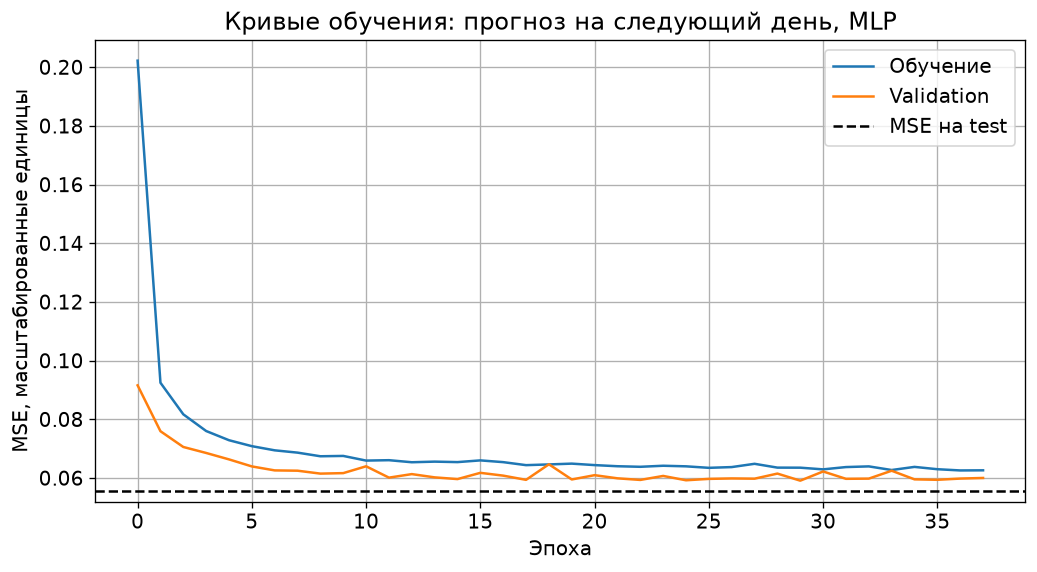

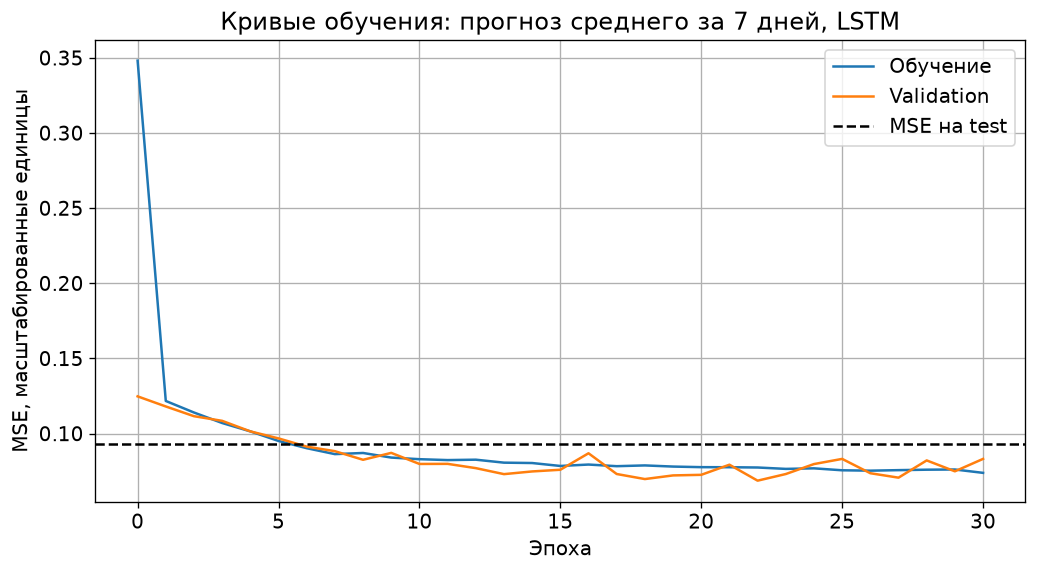

In [35]:
def evaluate_on_split(record, split_name):
    '''Считает прогноз и метрики выбранной модели на указанной выборке.'''
    data = data_cache[(record["task"], int(record["window"]))]
    mask = data["split"] == split_name
    X = data["X"][mask]
    if record["model"] != "MLP":
        X = X[..., None]

    model = trained_models[int(record["run_id"])]
    pred_scaled = model.predict(X, verbose=0).ravel()
    pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    metrics = calc_metrics(data["y_raw"][mask], pred)
    return metrics, pred, data["target_start"][mask], data["y_raw"][mask]


# Лучшая по validation конфигурация для каждой задачи
best_overall = (
    runs_frame()
    .sort_values("val_RMSE")
    .groupby("task", as_index=False)
    .head(1)
)
display(best_overall.reset_index(drop=True))

# Test: один раз оцениваем выбранную модель и строим кривые обучения
for _, record in best_overall.iterrows():
    data = data_cache[(record["task"], int(record["window"]))]
    mask = data["split"] == "test"
    X_test = data["X"][mask]
    if record["model"] != "MLP":
        X_test = X_test[..., None]
    pred_scaled = trained_models[int(record["run_id"])].predict(X_test, verbose=0).ravel()
    test_mse_scaled = mean_squared_error(data["y"][mask], pred_scaled)

    history = histories[int(record["run_id"])]
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(history.history["loss"], label="Обучение")
    ax.plot(history.history["val_loss"], label="Validation")
    ax.axhline(test_mse_scaled, color="black", linestyle="--", label="MSE на test")
    ax.set_title("Кривые обучения: " + TASK_TITLES[record["task"]] + ", " + MODEL_TITLES[record["model"]])
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("MSE, масштабированные единицы")
    ax.legend()
    fig.savefig(FIGURES_DIR / ("lab2-curves-" + record["task"] + ".png"), bbox_inches="tight")
    plt.show()

In [36]:
# Сохраняем лучшие модели и их конфигурации для воспроизводимости
for _, record in best_overall.iterrows():
    safe_name = record["task"].replace("_", "-")
    model_path = MODELS_DIR / ("lab2-" + safe_name + "-best.keras")
    trained_models[int(record["run_id"])].save(model_path)
    print("Сохранена модель:", model_path.name)

best_overall.drop(columns=["run_id"]).to_csv(
    RESULTS_DIR / "lab2-best-configs.csv", index=False, encoding="utf-8"
)
pd.DataFrame({"mean": [scaler.mean_[0]], "scale": [scaler.scale_[0]]}).to_csv(
    RESULTS_DIR / "lab2-scaler.csv", index=False, encoding="utf-8"
)

Сохранена модель: lab2-next-day-best.keras
Сохранена модель: lab2-weekly-mean-best.keras


**Результат:** у обеих лучших моделей train и validation loss быстро снижаются и выходят на плато. Для MLP на следующем дне MSE на тесте 0,0556 в масштабированных единицах. Для LSTM на недельном среднем MSE на тесте 0,0930. Кривые train и validation не расходятся, признаков переобучения нет. Небольшое превышение тестовой ошибки над validation ожидаемо: тест - более поздний период.

## Итоговая оценка на тестовой выборке

Для каждой задачи берется лучшая по validation конфигурация каждой архитектуры, после чего все они один раз оцениваются на тесте. В таблицу также включены наивные прогнозы. Метрики считаются в градусах Цельсия.

In [37]:
# Итоговая таблица: лучшая модель каждого типа и базовые прогнозы на test
best_by_model = (
    runs_frame()
    .sort_values("val_RMSE")
    .groupby(["task", "model"], as_index=False)
    .head(1)
)

final_rows = []
for task in TASKS:
    task_best = best_by_model[best_by_model["task"] == task]
    for _, record in task_best.iterrows():
        metrics, _, _, _ = evaluate_on_split(record, "test")
        final_rows.append({
            "task": task,
            "model": MODEL_TITLES[record["model"]],
            "window": int(record["window"]),
            "units": int(record["units"]),
            "dropout": float(record["dropout"]),
            "params": int(record["params"]),
            **metrics,
        })

    data = make_task_data(task, min(WINDOW_LENGTHS))
    mask = data["split"] == "test"
    for method, title in [("persistence", "Naive (persistence)"), ("seasonal", "Seasonal naive")]:
        metrics = calc_metrics(data["y_raw"][mask], naive_predictions(data, method)[mask])
        final_rows.append({
            "task": task,
            "model": title,
            "window": np.nan,
            "units": np.nan,
            "dropout": np.nan,
            "params": np.nan,
            **metrics,
        })

final_table = pd.DataFrame(final_rows)
final_table[["MAE", "MSE", "RMSE", "R2"]] = final_table[["MAE", "MSE", "RMSE", "R2"]].round(4)

next_day_table = final_table[final_table["task"] == "next_day"].drop(columns="task")
weekly_table = final_table[final_table["task"] == "weekly_mean"].drop(columns="task")
next_day_table.to_csv(RESULTS_DIR / "lab2-next-day-metrics.csv", index=False, encoding="utf-8")
weekly_table.to_csv(RESULTS_DIR / "lab2-weekly-metrics.csv", index=False, encoding="utf-8")

print("Прогноз на следующий день")
display(next_day_table.reset_index(drop=True))
print("Прогноз среднего за 7 дней")
display(weekly_table.reset_index(drop=True))

Прогноз на следующий день


,model,window,units,dropout,params,MAE,MSE,RMSE,R2,n
0,MLP,7.0,64.0,0.0,577.0,1.2175,2.9050,1.7044,0.9458,549
1,LSTM,60.0,32.0,0.0,4385.0,1.2158,2.8011,1.6736,0.9477,549
2,SimpleRNN,7.0,32.0,0.0,1121.0,1.2361,2.8996,1.7028,0.9459,549
3,Stacked LSTM,7.0,32.0,0.0,12705.0,1.2174,2.8296,1.6821,0.9472,549
4,Naive (persistence),NaN,NaN,NaN,NaN,1.2386,2.9254,1.7104,0.9454,549
5,Seasonal naive,NaN,NaN,NaN,NaN,3.2556,16.8051,4.0994,0.6862,549


Прогноз среднего за 7 дней


,model,window,units,dropout,params,MAE,MSE,RMSE,R2,n
0,LSTM,60.0,32.0,0.0,4385.0,1.6116,4.8585,2.2042,0.9026,543
1,SimpleRNN,60.0,32.0,0.0,1121.0,1.5994,4.6617,2.1591,0.9065,543
2,Stacked LSTM,14.0,32.0,0.0,12705.0,1.6709,4.8803,2.2091,0.9021,543
3,MLP,7.0,32.0,0.0,289.0,1.7427,5.4030,2.3244,0.8916,543
4,Naive (persistence),NaN,NaN,NaN,NaN,2.0021,7.2089,2.6849,0.8554,543
5,Seasonal naive,NaN,NaN,NaN,NaN,2.6979,11.0069,3.3177,0.7792,543


**Результат:** на тесте все нейросети превзошли persistence. Для следующего дня: MLP - RMSE 1,7044 °C (R2 0,9458); LSTM - RMSE 1,6736 °C (R2 0,9477); SimpleRNN - RMSE 1,7028 °C (R2 0,9459); Stacked LSTM - RMSE 1,6821 °C (R2 0,9472); Naive (persistence) - RMSE 1,7104 °C (R2 0,9454); Seasonal naive - RMSE 4,0994 °C (R2 0,6862). Лучший RMSE у LSTM. Для недельного среднего: LSTM - RMSE 2,2042 °C (R2 0,9026); SimpleRNN - RMSE 2,1591 °C (R2 0,9065); Stacked LSTM - RMSE 2,2091 °C (R2 0,9021); MLP - RMSE 2,3244 °C (R2 0,8916); Naive (persistence) - RMSE 2,6849 °C (R2 0,8554); Seasonal naive - RMSE 3,3177 °C (R2 0,7792). Лучший RMSE у SimpleRNN. Все модели достигли R2 выше 0,89, то есть ориентир 0,80 выполнен.

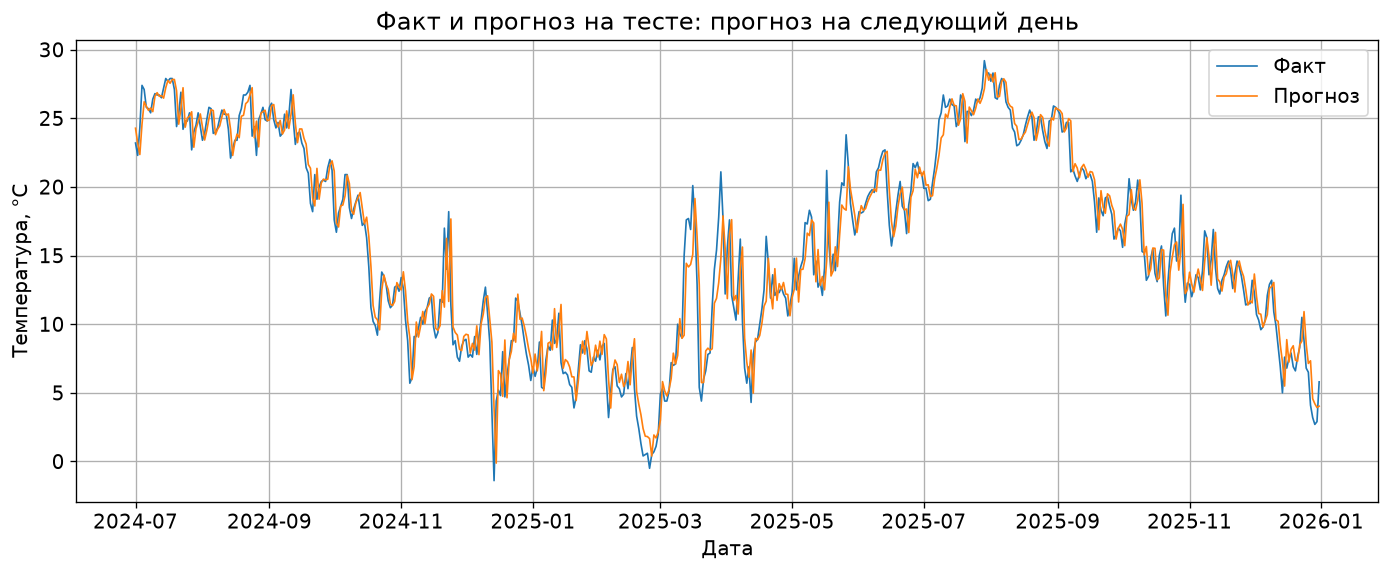

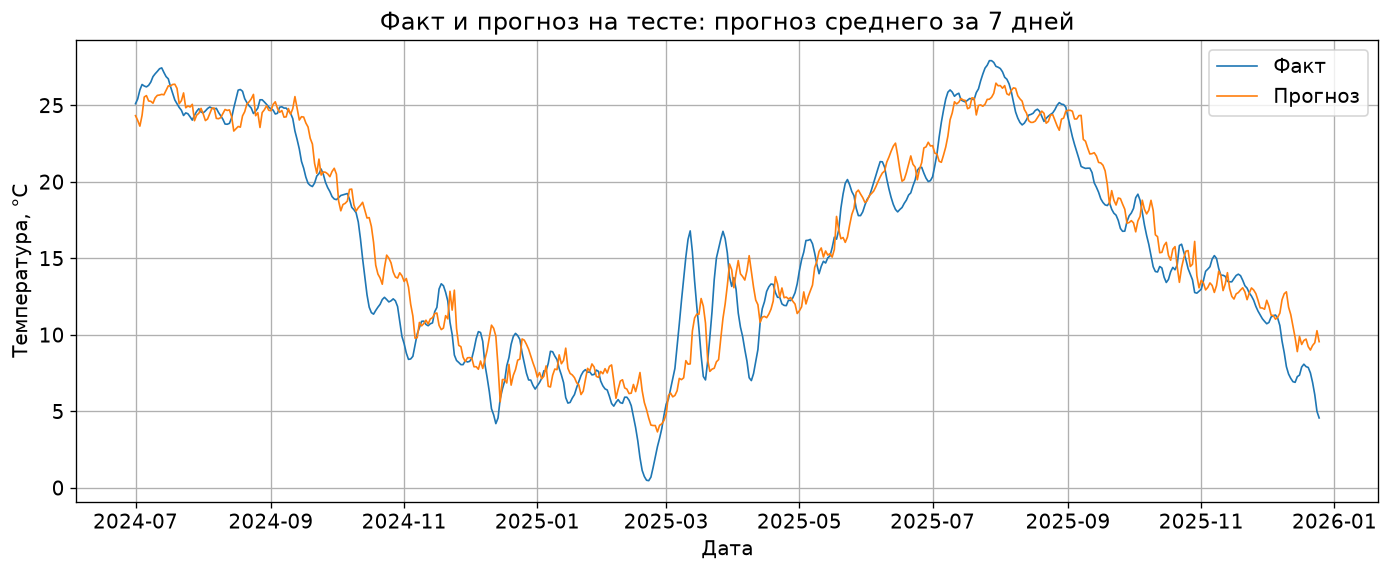

In [38]:
# График "факт - прогноз" для выбранной модели каждой задачи
for _, record in best_overall.iterrows():
    metrics, pred, dates, true = evaluate_on_split(record, "test")
    title = TASK_TITLES[record["task"]]

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(dates, true, color="tab:blue", linewidth=1.0, label="Факт")
    ax.plot(dates, pred, color="tab:orange", linewidth=1.0, label="Прогноз")
    ax.set_title("Факт и прогноз на тесте: " + title)
    ax.set_xlabel("Дата")
    ax.set_ylabel("Температура, °C")
    ax.legend()
    fig.savefig(FIGURES_DIR / ("lab2-forecast-" + record["task"] + ".png"), bbox_inches="tight")
    plt.show()

**Результат:** на тестовом интервале обе выбранные модели повторяют сезонный ход температуры. Для следующего дня MLP (RMSE 1,7044 °C, R² 0,9458) хорошо отслеживает суточные колебания, но сглаживает отдельные резкие всплески. Для недельного среднего LSTM (RMSE 2,2042 °C, R² 0,9026) даёт более гладкую кривую, что ожидаемо для среднего за семь дней. Систематического сдвига на всём интервале не видно.

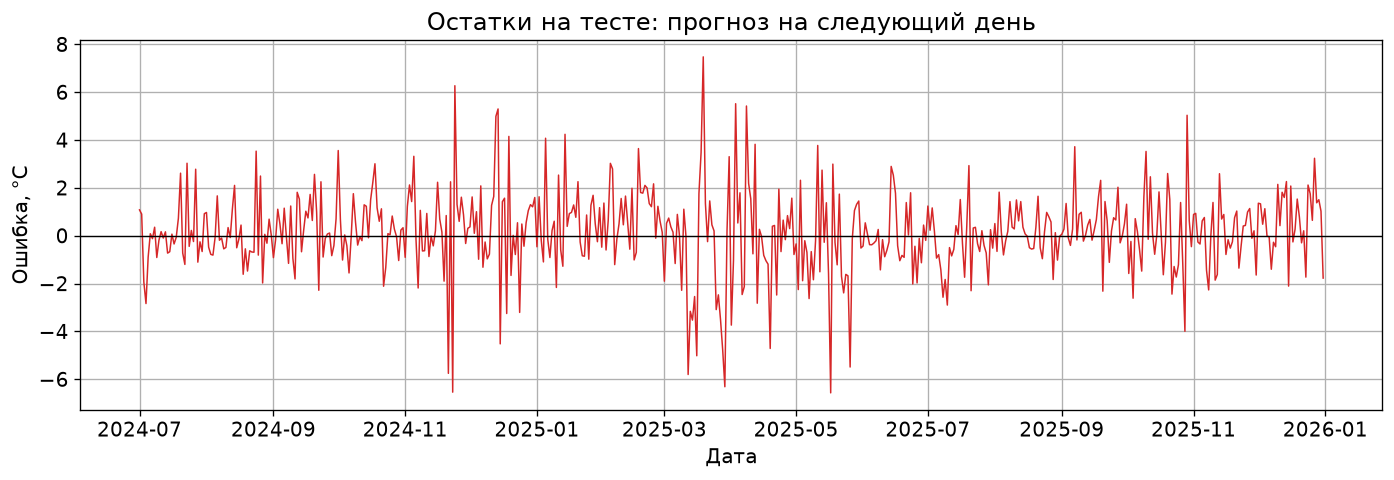

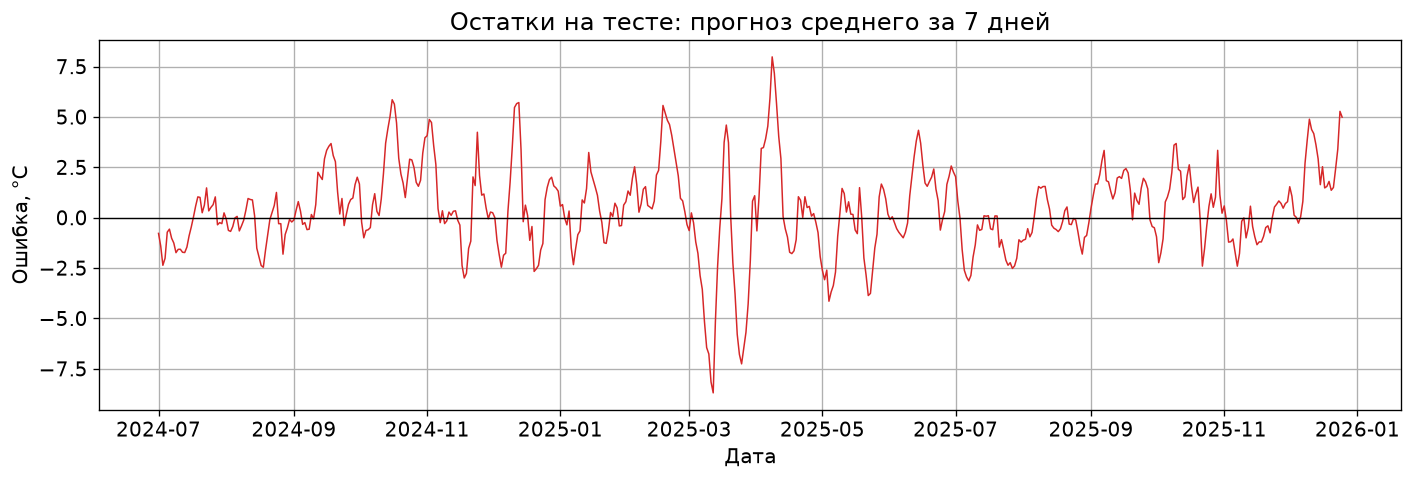

In [39]:
# График остатков: проверяем смещение и разброс ошибки
for _, record in best_overall.iterrows():
    metrics, pred, dates, true = evaluate_on_split(record, "test")
    residuals = pred - true
    title = TASK_TITLES[record["task"]]

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(dates, residuals, color="tab:red", linewidth=0.9)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("Остатки на тесте: " + title)
    ax.set_xlabel("Дата")
    ax.set_ylabel("Ошибка, °C")
    fig.savefig(FIGURES_DIR / ("lab2-residuals-" + record["task"] + ".png"), bbox_inches="tight")
    plt.show()

**Результат:** остатки обеих моделей колеблются вокруг нуля без выраженного тренда, то есть систематического смещения нет. Для следующего дня разброс ошибок больше, а отдельные всплески совпадают с резкими изменениями погоды; для недельного среднего остатки меньше и глаже за счёт усреднения. Ошибка на test сопоставима с validation, поэтому признаков переобучения по остаткам не видно.

## Дополнительный эксперимент: другие погодные признаки

В основных экспериментах модель видела только среднюю температуру за прошлые дни. Здесь обе задачи проверяются с расширенным входом: в лучшие конфигурации каждой задачи подаются еще несколько погодных признаков, и по validation и test видно, дает ли это прирост качества или только усложняет модель.

Кандидаты: минимальная и максимальная температура, осадки, скорость и направление ветра, давление, высота снега, порыв ветра и продолжительность солнца. Сначала каждый признак проверяется на пропуски, выбросы и связь с целевой температурой.

### Проверка кандидатов

Пропуски и выбросы считаем по всему ряду, а границы выбросов по правилу 1,5 IQR - только по train, чтобы не подглядывать в validation и test.

In [40]:
# Кандидаты в дополнительные признаки: пропуски, выбросы и связь с целевой температурой
CANDIDATE_FEATURES = ["tmin", "tmax", "prcp", "wspd", "pres", "wdir", "snow", "wpgt", "tsun"]
train_mask_features = weather["date"] <= train_end

candidate_rows = []
for feature in CANDIDATE_FEATURES:
    values_train = weather.loc[train_mask_features, feature]
    has_values = bool(values_train.notna().any())
    q1 = values_train.quantile(0.25)
    q3 = values_train.quantile(0.75)
    spread = q3 - q1
    lower_bound = q1 - 1.5 * spread
    upper_bound = q3 + 1.5 * spread
    outliers = ((weather[feature] < lower_bound) | (weather[feature] > upper_bound)).sum()

    candidate_rows.append({
        "признак": feature,
        "пропусков": int(weather[feature].isna().sum()),
        "доля пропусков, %": round(100 * float(weather[feature].isna().mean()), 1),
        "асимметрия": round(float(weather[feature].skew()), 2) if has_values else np.nan,
        "выбросов по 1,5 IQR": int(outliers) if has_values else np.nan,
        "корреляция с tavg": round(float(weather[feature].corr(weather["tavg"])), 3) if has_values else np.nan,
    })

candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table)

,признак,пропусков,"доля пропусков, %",асимметрия,"выбросов по 1,5 IQR",корреляция с tavg
0,tmin,0,0.0,0.03,0.0,0.973
1,tmax,1,0.0,-0.13,0.0,0.978
2,prcp,201,5.5,4.28,687.0,-0.144
3,wspd,25,0.7,0.79,100.0,-0.076
4,pres,99,2.7,0.25,6.0,-0.630
5,wdir,259,7.1,0.95,164.0,0.262
6,snow,3629,99.3,0.91,0.0,-0.208
7,wpgt,3653,100.0,NaN,NaN,NaN
8,tsun,3653,100.0,NaN,NaN,NaN


**Результат:** четыре кандидата отпадают сразу. `tmin` и `tmax` почти повторяют `tavg` (корреляция 0,973 и 0,978) - это мультиколлинеарность: новой информации они не добавляют, только увеличивают размер входа. `wpgt` и `tsun` пусты полностью, `snow` имеет 3629 пропусков (99,3 %), а `wdir` - круговой угол, где 0 и 360 градусов означают одно направление, поэтому его нужно кодировать синусом и косинусом, а не подавать как число. Остаются `prcp`, `wspd` и `pres`; пропусков у них 201 (5,5 %), 25 (0,7 %) и 99 (2,7 %), их заполняем медианами train. По правилу 1,5 IQR формально выходит 687, 100 и 6 выбросов. Для осадков правило непригодно: медиана равна нулю, поэтому каждый дождь попадает за верхнюю границу, а распределение сильно скошено (асимметрия 4,28). Вместо удаления или обрезки применяем логарифм `log1p`: он сжимает тяжелый хвост и сохраняет информацию о сильных дождях. У `wspd` и `pres` выбросов мало (2,7 % и 0,2 %), это реальные шторма и аномалии давления, поэтому строки не удаляем.

### Подготовка признаков

Средняя температура берется уже в масштабе `scaler`, обученном на train в основном эксперименте, поэтому цели и метрики остаются сопоставимыми. Три дополнительных признака заполняются медианами train и масштабируются отдельным `StandardScaler`, который тоже обучается только на train. Осадки перед масштабированием переводятся в логарифмическую шкалу `log1p`: так редкие ливни не доминируют в масштабе и информация о них сохраняется.

In [41]:
# Дополнительные признаки, которые прошли проверку: осадки, скорость ветра и давление
EXTRA_FEATURES = ["prcp", "wspd", "pres"]
FEATURE_COLUMNS = ["tavg"] + EXTRA_FEATURES


def prepare_extra_features(frame):
    '''Возвращает дополнительные признаки с логарифмом осадков.'''
    prepared = frame[EXTRA_FEATURES].copy()
    prepared["prcp"] = np.log1p(prepared["prcp"])
    return prepared


# Медианы для заполнения пропусков - только по train
train_prepared = prepare_extra_features(weather.loc[train_mask_features])
fill_values = train_prepared.median()
extra_filled = prepare_extra_features(weather).fillna(fill_values)

# Масштабирование тоже обучаем только на train
feature_scaler = StandardScaler()
feature_scaler.fit(extra_filled.loc[train_mask_features])
extra_scaled = feature_scaler.transform(extra_filled).astype("float32")

# Вход одного дня: средняя температура в масштабе основного эксперимента плюс три признака
model_input = np.column_stack([
    weather["tavg_scaled"].to_numpy(dtype="float32"),
    extra_scaled,
]).astype("float32")

print("Пропусков в дополнительных признаках до заполнения:", int(weather[EXTRA_FEATURES].isna().sum().sum()))
print("Форма входа одного дня:", model_input.shape)
display(pd.DataFrame({
    "признак": EXTRA_FEATURES,
    "медиана train": fill_values.to_numpy().round(3),
    "среднее train": feature_scaler.mean_.round(3),
    "стандартное отклонение": feature_scaler.scale_.round(3),
}))

Пропусков в дополнительных признаках до заполнения: 325
Форма входа одного дня: (3653, 4)


,признак,медиана train,среднее train,стандартное отклонение
0,prcp,0.0,0.631,1.098
1,wspd,11.4,11.680,2.887
2,pres,1015.1,1015.359,5.914


### Скользящие окна

Окна строятся так же, как в основном эксперименте: те же длины, те же цели для обеих задач и та же разметка по датам, но в каждом дне окна теперь четыре числа вместо одного. Для MLP окно разворачивается в плоский вектор, рекуррентные модели получают последовательность из четырех признаков.

In [42]:
def make_feature_data(task, window):
    '''Строит окна из четырех признаков; цели и разбиение совпадают с базовым экспериментом.'''
    values_scaled = weather["tavg_scaled"].to_numpy(dtype="float32")
    values_raw = weather["tavg"].to_numpy(dtype="float32")
    dates = pd.DatetimeIndex(weather["date"])
    horizon = 1 if task == "next_day" else WEEKLY_HORIZON

    X, y_scaled, y_raw, target_start, target_end = [], [], [], [], []
    last_start = len(weather) - horizon
    for i in range(window, last_start + 1):
        # Вход - окно из window дней, в каждом дне четыре признака
        X.append(model_input[i - window:i])
        if task == "next_day":
            y_scaled.append(values_scaled[i])
            y_raw.append(values_raw[i])
        else:
            y_scaled.append(values_scaled[i:i + horizon].mean())
            y_raw.append(values_raw[i:i + horizon].mean())
        target_start.append(dates[i])
        target_end.append(dates[i + horizon - 1])

    X = np.asarray(X, dtype="float32")
    y_scaled = np.asarray(y_scaled, dtype="float32")
    y_raw = np.asarray(y_raw, dtype="float32")
    target_start = pd.DatetimeIndex(target_start)
    target_end = pd.DatetimeIndex(target_end)

    # Та же разметка по датам цели: окна на стыке выборок попадают в gap
    split = np.full(len(y_scaled), "gap", dtype=object)
    split[target_end <= train_end] = "train"
    split[(target_start >= val_start) & (target_end <= val_end)] = "val"
    split[target_start >= test_start] = "test"

    return {
        "task": task,
        "window": window,
        "X": X,
        "y": y_scaled,
        "y_raw": y_raw,
        "target_start": target_start,
        "target_end": target_end,
        "split": split,
    }


# MLP получает плоское окно, рекуррентные модели - последовательность из четырех признаков
def reshape_for_model(X, model_type):
    if model_type == "MLP":
        return X.reshape(len(X), -1)
    return X

### Обучение и сравнение

Каждая из четырех лучших конфигураций каждой задачи обучается заново на тех же окнах и с теми же правилами: MSE, batch size 32, до 80 эпох, EarlyStopping с patience 8, тот же оптимизатор и Dropout. Отличается только вход: вместо одного числа в день модель получает четыре признака. После обучения те же конфигурации один раз оцениваются на test.

In [43]:
# Те же лучшие конфигурации обеих задач, но с четырьмя признаками
best_configs = best_by_model.copy()

extra_rows = []
for _, record in best_configs.iterrows():
    data = make_feature_data(record["task"], int(record["window"]))
    masks = {name: data["split"] == name for name in ("train", "val", "test")}

    # Архитектура, число ячеек, оптимизатор и Dropout те же, меняется только вход
    model = build_model(
        record["model"],
        int(record["window"]),
        int(record["units"]),
        record["optimizer"],
        float(record["dropout"]),
        n_features=len(FEATURE_COLUMNS),
    )
    history, elapsed, early_stopping = train_model(
        model,
        reshape_for_model(data["X"][masks["train"]], record["model"]),
        data["y"][masks["train"]],
        reshape_for_model(data["X"][masks["val"]], record["model"]),
        data["y"][masks["val"]],
    )

    # Метрики в градусах Цельсия: прогноз возвращаем обратным масштабированием
    split_metrics = {}
    for split_name in ("val", "test"):
        X = reshape_for_model(data["X"][masks[split_name]], record["model"])
        pred_scaled = model.predict(X, verbose=0).ravel()
        pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
        split_metrics[split_name] = calc_metrics(data["y_raw"][masks[split_name]], pred)

    extra_rows.append({
        "task": record["task"],
        "model": record["model"],
        "features": len(FEATURE_COLUMNS),
        "window": int(record["window"]),
        "units": int(record["units"]),
        "params": int(model.count_params()),
        "val_RMSE": split_metrics["val"]["RMSE"],
        "val_R2": split_metrics["val"]["R2"],
        "test_RMSE": split_metrics["test"]["RMSE"],
        "test_R2": split_metrics["test"]["R2"],
    })
    print(
        record["task"], MODEL_TITLES[record["model"]],
        "L =", int(record["window"]), "units =", int(record["units"]),
        "эпох =", len(history.history["loss"]),
        "val RMSE =", round(split_metrics["val"]["RMSE"], 4),
        "test RMSE =", round(split_metrics["test"]["RMSE"], 4),
        "время =", round(elapsed, 1), "с",
    )

extra_table = pd.DataFrame(extra_rows)
display(extra_table.round(4).reset_index(drop=True))

next_day MLP L = 7 units = 64 эпох = 32 val RMSE = 2.0164 test RMSE = 1.8263 время = 24.1 с


next_day LSTM L = 60 units = 32 эпох = 51 val RMSE = 1.7034 test RMSE = 1.6025 время = 49.3 с


next_day SimpleRNN L = 7 units = 32 эпох = 32 val RMSE = 1.7637 test RMSE = 1.6638 время = 49.9 с


next_day Stacked LSTM L = 7 units = 32 эпох = 32 val RMSE = 1.7232 test RMSE = 1.6331 время = 39.4 с


weekly_mean LSTM L = 60 units = 32 эпох = 13 val RMSE = 2.2425 test RMSE = 2.4254 время = 12.7 с


weekly_mean SimpleRNN L = 60 units = 32 эпох = 22 val RMSE = 2.0496 test RMSE = 2.1263 время = 129.3 с


weekly_mean Stacked LSTM L = 14 units = 32 эпох = 22 val RMSE = 2.3396 test RMSE = 2.3286 время = 26.7 с


weekly_mean MLP L = 7 units = 32 эпох = 23 val RMSE = 2.2043 test RMSE = 2.422 время = 18.5 с


,task,model,features,window,units,params,val_RMSE,val_R2,test_RMSE,test_R2
0,next_day,MLP,4,7,64,1921,2.0164,0.9122,1.8263,0.9377
1,next_day,LSTM,4,60,32,4769,1.7034,0.9373,1.6025,0.9521
2,next_day,SimpleRNN,4,7,32,1217,1.7637,0.9328,1.6638,0.9483
3,next_day,StackedLSTM,4,7,32,13089,1.7232,0.9359,1.6331,0.9502
4,weekly_mean,LSTM,4,60,32,4769,2.2425,0.8819,2.4254,0.8820
5,weekly_mean,SimpleRNN,4,60,32,1217,2.0496,0.9014,2.1263,0.9093
6,weekly_mean,StackedLSTM,4,14,32,13089,2.3396,0.8715,2.3286,0.8912
7,weekly_mean,MLP,4,7,32,961,2.2043,0.8859,2.4220,0.8823


In [44]:
# Сравнение на validation и test для обеих задач: одна температура против четырех признаков
base_rows = []
for _, record in best_configs.iterrows():
    test_row = final_table[
        (final_table["task"] == record["task"])
        & (final_table["model"] == MODEL_TITLES[record["model"]])
    ].iloc[0]
    base_rows.append({
        "task": record["task"],
        "model": record["model"],
        "features": 1,
        "window": int(record["window"]),
        "units": int(record["units"]),
        "params": int(record["params"]),
        "val_RMSE": float(record["val_RMSE"]),
        "val_R2": float(record["val_R2"]),
        "test_RMSE": float(test_row["RMSE"]),
        "test_R2": float(test_row["R2"]),
    })
base_table = pd.DataFrame(base_rows)

# Длинная таблица: каждая конфигурация в двух вариантах набора признаков
feature_comparison = pd.concat([base_table, extra_table], ignore_index=True)
feature_comparison["model"] = feature_comparison["model"].map(MODEL_TITLES)
feature_comparison["features"] = feature_comparison["features"].map(
    lambda count: "только tavg" if count == 1 else "четыре признака"
)
feature_comparison = feature_comparison[
    ["task", "model", "features", "window", "units", "params", "val_RMSE", "val_R2", "test_RMSE", "test_R2"]
]
feature_comparison.round(4).to_csv(
    RESULTS_DIR / "lab2-extra-features.csv", index=False, encoding="utf-8"
)
display(feature_comparison.round(4).reset_index(drop=True))

# Прирост качества: отрицательная разница RMSE означает улучшение
delta_rows = []
for task, model_title in feature_comparison[["task", "model"]].drop_duplicates().itertuples(index=False):
    base = feature_comparison[
        (feature_comparison["task"] == task)
        & (feature_comparison["model"] == model_title)
        & (feature_comparison["features"] == "только tavg")
    ].iloc[0]
    extra = feature_comparison[
        (feature_comparison["task"] == task)
        & (feature_comparison["model"] == model_title)
        & (feature_comparison["features"] == "четыре признака")
    ].iloc[0]
    delta_rows.append({
        "task": task,
        "model": model_title,
        "d_RMSE_val": extra["val_RMSE"] - base["val_RMSE"],
        "d_RMSE_test": extra["test_RMSE"] - base["test_RMSE"],
        "d_R2_test": extra["test_R2"] - base["test_R2"],
    })
delta_table = pd.DataFrame(delta_rows)
display(delta_table.round(4).reset_index(drop=True))

,task,model,features,window,units,params,val_RMSE,val_R2,test_RMSE,test_R2
0,next_day,MLP,только tavg,7,64,577,1.7567,0.9333,1.7044,0.9458
1,next_day,LSTM,только tavg,60,32,4385,1.7814,0.9315,1.6736,0.9477
2,next_day,SimpleRNN,только tavg,7,32,1121,1.7863,0.9311,1.7028,0.9459
3,next_day,Stacked LSTM,только tavg,7,32,12705,1.7868,0.9310,1.6821,0.9472
4,weekly_mean,LSTM,только tavg,60,32,4385,1.8937,0.9158,2.2042,0.9026
5,weekly_mean,SimpleRNN,только tavg,60,32,1121,1.9804,0.9079,2.1591,0.9065
6,weekly_mean,Stacked LSTM,только tavg,14,32,12705,2.0744,0.8989,2.2091,0.9021
7,weekly_mean,MLP,только tavg,7,32,289,2.0917,0.8973,2.3244,0.8916
8,next_day,MLP,четыре признака,7,64,1921,2.0164,0.9122,1.8263,0.9377
9,next_day,LSTM,четыре признака,60,32,4769,1.7034,0.9373,1.6025,0.9521


,task,model,d_RMSE_val,d_RMSE_test,d_R2_test
0,next_day,MLP,0.2597,0.1219,-0.0081
1,next_day,LSTM,-0.0780,-0.0711,0.0044
2,next_day,SimpleRNN,-0.0226,-0.0390,0.0024
3,next_day,Stacked LSTM,-0.0636,-0.0490,0.0030
4,weekly_mean,LSTM,0.3488,0.2212,-0.0206
5,weekly_mean,SimpleRNN,0.0692,-0.0328,0.0028
6,weekly_mean,Stacked LSTM,0.2652,0.1195,-0.0109
7,weekly_mean,MLP,0.1126,0.0976,-0.0093


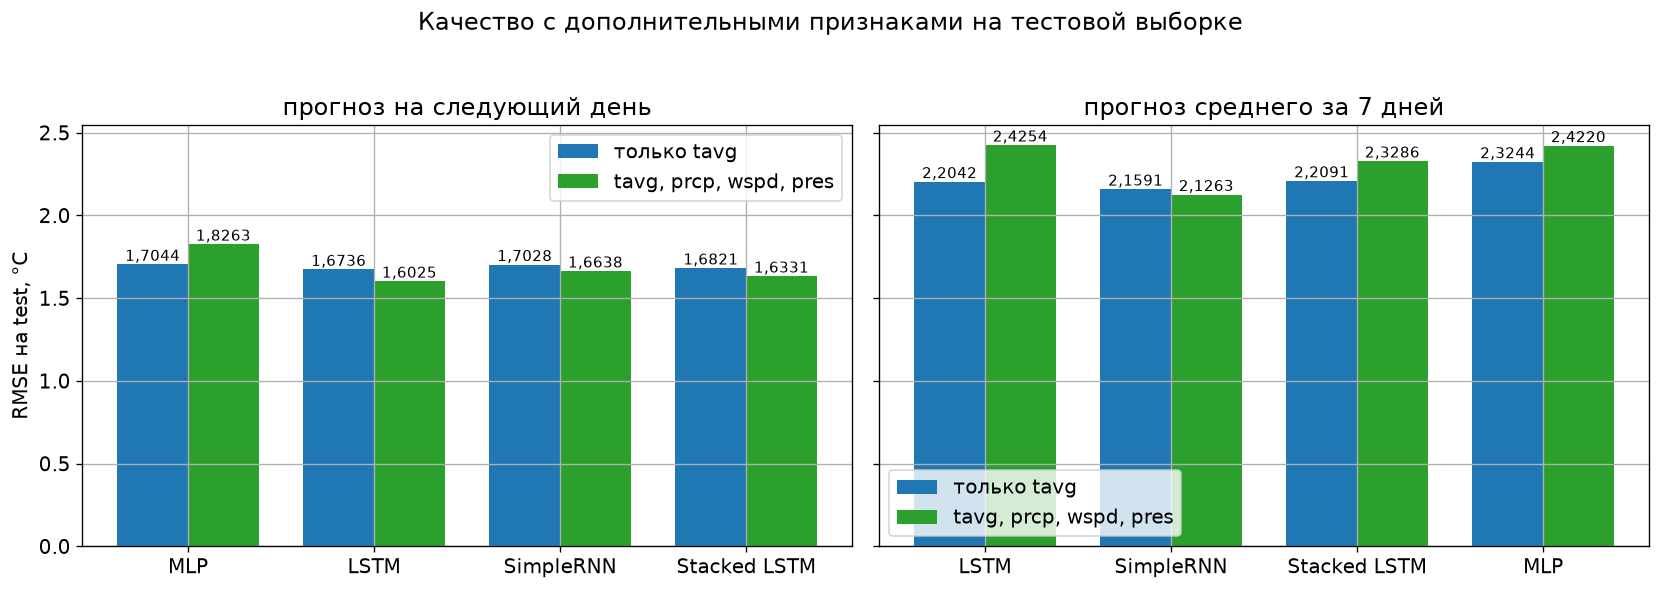

In [45]:
# RMSE на test: одна температура против четырех признаков, отдельная панель для каждой задачи
def comparison_value(task, model_title, feature_title):
    '''Достает RMSE на test для нужной задачи и варианта набора признаков.'''
    row = feature_comparison[
        (feature_comparison["task"] == task)
        & (feature_comparison["model"] == model_title)
        & (feature_comparison["features"] == feature_title)
    ].iloc[0]
    return float(row["test_RMSE"])


width = 0.38
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for position, (axis, task) in enumerate(zip(axes, TASKS)):
    model_titles = [
        MODEL_TITLES[model_type]
        for model_type in best_configs.loc[best_configs["task"] == task, "model"]
    ]
    positions = np.arange(len(model_titles))
    base_values = [comparison_value(task, title, "только tavg") for title in model_titles]
    extra_values = [comparison_value(task, title, "четыре признака") for title in model_titles]

    bars_base = axis.bar(positions - width / 2, base_values, width,
                         label="только tavg", color="tab:blue")
    bars_extra = axis.bar(positions + width / 2, extra_values, width,
                          label="tavg, prcp, wspd, pres", color="tab:green")
    axis.set_xticks(positions)
    axis.set_xticklabels(model_titles)
    axis.set_title(TASK_TITLES[task])
    if position == 0:
        axis.set_ylabel("RMSE на test, °C")
    axis.legend()
    for bar in list(bars_base) + list(bars_extra):
        axis.annotate(
            f"{bar.get_height():.4f}".replace(".", ","),
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center", va="bottom", fontsize=9,
        )

fig.suptitle("Качество с дополнительными признаками на тестовой выборке")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGURES_DIR / "lab2-extra-features.png", bbox_inches="tight")
plt.show()

**Результат:** дополнительные признаки дали разный эффект в двух задачах. Для следующего дня три рекуррентные модели улучшились: LSTM - RMSE 1,6736 -> 1,6025 °C (R2 0,9477 -> 0,9521), Stacked LSTM - 1,6821 -> 1,6331 °C, SimpleRNN - 1,7028 -> 1,6638 °C. MLP, наоборот, ухудшилась: 1,7044 -> 1,8263 °C. Для недельного среднего выигрыш только у SimpleRNN: 2,1591 -> 2,1263 °C (R2 0,9065 -> 0,9093), а LSTM (2,2042 -> 2,4254 °C), Stacked LSTM (2,2091 -> 2,3286 °C) и MLP (2,3244 -> 2,4220 °C) стали хуже. Причина в самой задаче: для следующего дня давление и температура текущего момента прямо связаны с погодой, поэтому дополнительные входы помогают, а для среднего за следующие семь дней осадки, ветер и давление почти не несут информации о будущем и работают как шум. Это видно и по validation: у LSTM на недельном среднем ошибка выросла с 1,8937 до 2,2425 °C. У SimpleRNN на недельном среднем validation тоже ухудшилась (1,9804 -> 2,0496 °C), а test немного улучшился, поэтому уверенного выигрыша здесь нет. Выбор конфигураций по-прежнему сделан по validation в экспериментах с одной температурой, а этот опыт только проверяет, что дают дополнительные признаки.

## Вывод:

В работе построены четыре нейросетевые модели для двух задач прогнозирования температуры в Сочи по данным Meteostat за 2016-2025 годы. Данные проверены на пропуски, дубликаты и выбросы, разбиты строго по времени, масштабирование обучено только на train, целевые интервалы validation и test не пересекаются с train.

Лучшей по validation для следующего дня стала MLP с окном 7 дней и 64 нейронами (RMSE 1,7567 °C, R2 0,9333). На тесте: RMSE 1,7044 °C, R2 0,9458. Лучшей по validation для недельного среднего стала LSTM с окном 60 дней и 32 ячейками (RMSE 1,8937 °C, R2 0,9158). На тесте: RMSE 2,2042 °C, R2 0,9026.

Все архитектуры превзошли persistence: для следующего дня - на 0,0060-0,0368 °C по RMSE, для недельного среднего - на 0,3605-0,5258 °C.

Увеличение до 64 нейронов помогло MLP в задаче на следующий день: RMSE 1,8050 -> 1,7567 °C. Adam немного превзошел RMSprop. Dropout не понадобился: по кривым обучения переобучения не было, а эксперимент с Dropout 0,2 ухудшил validation RMSE. 

Дополнительные погодные признаки проверены отдельным экспериментом: для следующего дня они помогли трем рекуррентным моделям (лучший результат у LSTM - RMSE 1,6025 °C), а для недельного среднего заметного выигрыша не дали. Основное ограничение работы — использование данных по одному городу и одному источнику. Дальше можно проверить более длинные входные окна и применить ансамбли моделей.